# Predicting CRISPRi knockdowns in cell lines nobody has perturbed

**Virtual Cell Challenge 2026: our final pipeline, end to end.** Helen Henry (University of Tampere), Nyle Hussain
(University of Glasgow), Kevin Henry.

**The story in one paragraph.** The challenge hands us three human cell lines, D, E and F, as about 18,400
resting ("control") cells each, and a list of 300 genes. For each gene it asks: if you switched this gene down
in this line, what would 400 of its cells look like, RNA molecule by RNA molecule? Nobody has run that
experiment on these lines, and we cannot either. But public experiments have switched many of the same genes
down in *other* cell lines. Our pipeline borrows those measured effects, decides how much to trust each one,
moves them onto the new line, and then draws realistic cells around them. In software terms: **stage 1** predicts a
diff (how much each gene's level changes), **stage 2** renders that diff into concrete samples, and the
grader runs a statistical test on the samples, so the rendering matters as much as the diff.

This notebook is the pipeline that built our final submission, not a reconstruction of it: run in FULL mode,
it rebuilds that file byte for byte from the public data and the challenge's controls.

## How to read this notebook

- **The story is in sections 1 to 15**, in four parts: understand the problem (1, 2), look at the data (3 to 7),
  build the pipeline one measured piece at a time (8 to 12), and the final file (13 to 15). Every section has
  the same shape: **the question**, **the experiment** (code you can rerun), **the figure**, **what we learned**
  (with the number the run printed) and **the playbook lesson**, a rule that holds beyond this challenge. The
  lessons are collected as a checklist at the end.
- **The code is in the package `vccpipe`** next to this notebook (thirteen modules, each a readable file), so the
  story starts right after the setup. Each section shows the function it teaches; its own cells are short steps
  that say what they compute, and every figure is drawn by one function of `vccpipe.plots`.
- **Every number and figure is computed by this notebook** from the public data and the challenge's controls.
  Scores of earlier versions on the challenge's leaderboard are quoted from our records and marked as quoted.
- **Colours mean the same thing everywhere**: line D blue, E orange, F aqua; the public training screens by
  tissue (blood violet, stem cells green, liver yellow, epithelial magenta); our method in near-black against a
  grey alternative; changes blue for down, red for up.
- **Run modes.** `FAST` (the default) runs the exploration on small public downloads, under an hour on a laptop.
  `FULL` rebuilds the final file (hours; ~80 GB of memory). The official scorer's statistics need a CUDA GPU:
  the sections that score (2, 8, 10, 15) say so and are skipped without one.

## Words we use

| word | meaning |
|---|---|
| **cell line** | a population of human cells grown in the lab from one donor or one tumour, so its cells are near-copies of each other |
| **gene expression, counts** | how many RNA molecules of each gene were captured from one cell: a cell is a vector of 18,533 whole numbers |
| **control cells** | cells given a guide that targets nothing ("non-targeting"): the unperturbed baseline |
| **knockdown, CRISPRi** | switching one gene's expression down: a guide RNA steers a disabled Cas9 protein, fused to a repressor, onto the gene's promoter (the DNA stretch where the gene's reading starts); the DNA itself is not cut |
| **screen, Perturb-seq** | an experiment that knocks down many genes, one per cell, and reads every cell's RNA |
| **log2 fold change** | log2 of (level after the knockdown / level in the controls): +1 doubled, -1 halved, 0 unchanged |
| **profile** | one knockdown's log2 fold change over all genes: the "diff" stage 1 predicts |
| **CPM** | counts per million: a gene's share of the counts, times a million (a level that does not depend on how deeply a cell was read) |
| **UMI, depth** | a molecule's barcode; a cell's depth is how many RNA molecules (UMIs) were counted in it |
| **pseudobulk** | many cells' counts added up into one profile |
| **Wilcoxon rank-sum test** | asks whether one group's values tend to rank above another's; the scorer runs it gene by gene, 400 predicted cells against the line's real controls |
| **called, significant** | a gene whose test p-value, corrected for testing thousands of genes at once (Benjamini-Hochberg), is below 0.05 |
| **10x Flex** | the lab method that measured the challenge's cells; screens measured with other methods see genes somewhat differently |
| **tissue, lineage** | the kind of cell a line comes from: blood, liver, brain, skin lining (epithelial) |
| **pluripotent stem cell (H1, iPSC)** | a cell that can still become any tissue; H1 is an embryonic stem-cell line, KOLF an induced one (iPSC) |
| **p53** | a protein that stops a stressed cell from growing; many cancer lines have lost it, and a line that has it answers some knockdowns differently |

## 0. Setup

`VCC_MODE`: `FAST` (default) runs the exploration on small public downloads; `FULL` rebuilds every reference table
and the final submission (hours, a machine with ~80 GB of memory). Paths: `VCC_NB_DATA` (default `data`) holds the
tables, the challenge's controls, the working files and the saved official scores (`data/scores`).

**Reproducibility is a feature you build first.** The final file is rebuilt here byte for byte, which needs three
things pinned: the library versions, the order of every floating-point sum, and the number of threads the linear
algebra library (BLAS) uses, because a matrix product split over more threads adds its numbers in a different order
and moves the last digit. The thread count is therefore fixed before numpy loads, and each step sets its own.

In [1]:
# The linear algebra library's thread count, fixed before numpy loads (each step then sets its own).
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "6")
os.environ.setdefault("OMP_NUM_THREADS", "6")
os.environ.setdefault("MKL_NUM_THREADS", "6")
os.environ.setdefault("NUMPY_MADVISE_HUGEPAGE", "0")
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")  # notices only: every check below raises on failure

In [2]:
# The run mode and the paths.
MODE = os.environ.get("VCC_MODE", "FAST").upper()
assert MODE in ("FAST", "FULL"), MODE
DATA = Path(os.environ.get("VCC_NB_DATA", "data"))
TABLES = Path(os.environ.get("VCC_TABLES", DATA / "tables"))  # the public screens as tables
PHASE = Path(os.environ.get("VCC_PHASE_DIR", DATA / "controls_final"))  # the final controls
WORK = Path(os.environ.get("VCC_WORK", DATA / "work"))
SUBMIT = os.environ.get("VCC_SUBMIT", "") == "yes"  # never on by default


def gpu_available() -> bool:
    """Whether a CUDA GPU is visible. The official scorer's DE engine (gpudge) needs one; without
    it, cell-eval2 falls back to another engine whose numbers differ. So the cells that report the
    scorer's numbers run only when a GPU is visible."""
    try:
        import torch

        return bool(torch.cuda.is_available())
    except Exception:  # noqa: BLE001
        return False


GPU = gpu_available()
print("mode", MODE, "| GPU for the scorer:", GPU)

mode FULL | GPU for the scorer: True


## The package

The pipeline's code lives in the package `vccpipe` next to this notebook: plain numpy and scipy in thirteen
documented modules (unit tests in `tests/`), so the story can start right away. Each section shows the function it
teaches (`show(...)` prints its source).

| module | what it holds | used in |
|---|---|---|
| `inputs` | the public screens as tables; each knockdown's borrowed profile, the significance gate, the neighbour prior | 4, 10, 13 |
| `constants`, `levels` | numbers fitted once on the training screens; the rank test's power from a line's own controls | 11, 13 |
| `combiner` | E, the learned combiner (a small ridge regression across cell types) | 10, 13 |
| `generator` | stage 2: from a predicted change to 400 cells of whole-number counts | 9, 11, 13 |
| `stage1` | stage 1's pieces, ending in each knockdown's targets | 10, 13 |
| `phase` | the entry points: `prepare_phase`, `probe_phase`, `predict_context`, `build_phase` | 13, 15 |
| `harness` | leave one line out, scored by the official scorer | 2, 8, 10, 15 |
| `figures`, `plots`, `labels` | the palette; one function per figure; display names and lookup tables | every figure |
| `rebuild`, `fast` | rebuilding the reference tables from public downloads; FAST mode's small inputs | appendix; FAST |

In [3]:
import json
import shutil
import subprocess
import sys
import zipfile

import anndata as ad

# pyplot first: the plotting backend sets its defaults, then the package sets its palette over them
import matplotlib.pyplot as plt  # noqa: F401
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.stats import false_discovery_control, norm

from vccpipe import *  # the package's functions, classes and constants, and `show`

EVIDENCE = {}  # each section's number behind its playbook lesson, recorded as the section runs

## FAST mode's data

In FAST mode the sections below read a small stand-in for the reference tables, built here from public files:
2,000 controls and 100 cells of each of 60 knockdowns per essential-gene line (K562, RPE1, HepG2, Jurkat), read
by byte range; the first 10,000 cells of the 2025 challenge's H1 validation split (FULL uses its training split);
the K562 genome-wide pseudobulk, the pathway screens and DepMap: about 3.5 GB in all. The numbers therefore
differ from a FULL run's; each one printed is computed from these data. KOLF, the other screens and the final
build are FULL only, and section 7's test needs FULL's 18,400 controls: with FAST's 2,000, even its planted
fluctuation is barely found. The reads are polite to the public servers: at most four connections to one
server, and a growing wait (or the server's own Retry-After) whenever one says it is busy. What was read is
kept under the downloads folder, so a rerun reads nothing twice.

In [4]:
if MODE == "FAST":
    TABLES = DATA / "fast"
    if not (TABLES / "phi.npz").exists():
        build_fast_tables(TABLES, Path(os.environ.get("VCC_DOWNLOADS", DATA / "downloads")), PHASE)
    print("FAST tables:", sorted(p.name for p in TABLES.iterdir()))

## 1. What is being asked

**The question.** What exactly goes in, and what must come out? Writing it down first settles what every
later piece has to produce.

**The input**, per cell line: about 18,400 unperturbed control cells, each a vector of whole-number RNA
counts over 18,533 genes, and the list of 300 genes to knock down. **The output**, per line and knockdown:
400 cells of whole-number counts over the same 18,533 genes, as if each gene had been switched down by
CRISPRi (a guide RNA steers a dead Cas9 fused to a repressor onto the gene's promoter; the DNA is not cut).
The model never sees a perturbed cell of the three final lines.

In [5]:
# The code this section is about (from the package):
show(read_phase)

def read_phase(phase_dir: Path):
    """The challenge's input description in `phase_dir`: (manifest, the gene axis, the panel of knockdowns)."""
    manifest = json.loads((phase_dir / "manifest.json").read_text())
    genes = pd.read_csv(phase_dir / "gene_names.csv")["gene_name"].tolist()
    perts = pd.read_csv(phase_dir / "pert_counts.csv")["target_gene"].tolist()
    assert len(genes) == manifest["n_genes"] and len(perts) == manifest["n_constructs"]
    return manifest, genes, perts

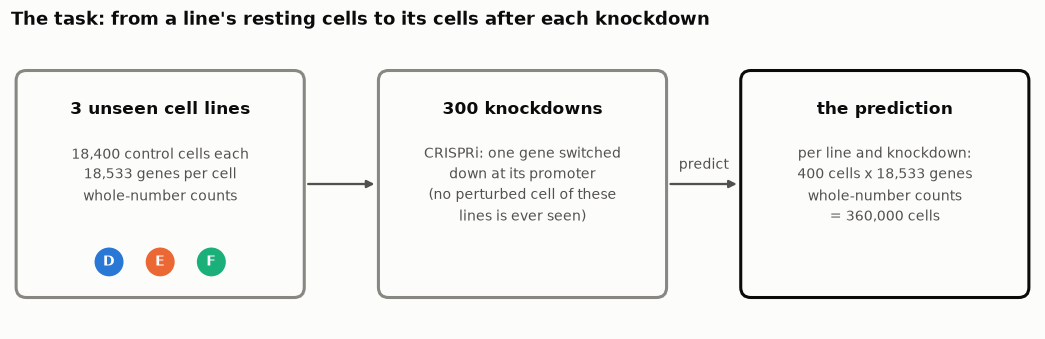

In [6]:
# The challenge's input: the lines, the gene axis and the panel of knockdowns.
manifest, final_genes, final_panel = read_phase(PHASE)
contexts = list(manifest["contexts"])
per_line = manifest.get("per_context", {})
n_control = per_line[contexts[0]]["control_cells"] if per_line else None
n_lines, n_kds, n_genes = len(contexts), len(final_panel), len(final_genes)
fig = plot_task(contexts, n_control, n_genes, n_kds)
EVIDENCE[1] = f"{n_lines} lines x {n_kds} knockdowns x 400 cells x {n_genes:,} genes"

**The playbook lesson.** Write down the input and the output, with their exact shapes, before anything else.

## 2. The scorer is the spec

**The question.** What does the official scorer reward? Its six measures (PDS, MSE, NMAE, FID, REACH, JAC)
read two different summaries of the submitted cells: PDS and MSE read each knockdown's pooled profile;
NMAE, FID, REACH and JAC read which genes a per-gene Wilcoxon rank test (400 predicted cells against the
real controls) calls significant, and in which direction. A prediction can be right on average and still
wrong where the test looks.

**The experiment.** A toy line built in the notebook: 300 genes, 2,000 control cells and 8 knockdowns of 200
cells each, every gene a negative binomial; each knockdown moves 20 genes by a log2 fold change of +-1 and
silences its own gene. Four predictions are scored by the official scorer against it, on the challenge's
scale (0 = the control-mean baseline, 1 = a split-half replicate of the real data):
- **replicate**: a fresh draw from the true distribution, what a perfect model would produce;
- **right means, wrong shape**: every cell of a knockdown at that knockdown's true mean (rounded up or down
  at random, so the mean is exact): no cell-to-cell variation;
- **noisy**: the true effects plus a random effect of the same size on 40 other genes;
- **no effect**: control-like cells for every knockdown.

In [7]:
# The code this section is about (from the package):
show(ControlRanks)

class ControlRanks:
    """The scorer's rank-sum test against fixed controls, exactly (average ranks, tie-corrected normal
    approximation, no continuity correction). Per tested gene: the controls' sorted CPM and tie sum."""

    def __init__(self, controls, tested: np.ndarray):
        """`controls`: the line's control cells (cells x genes, counts); `tested`: a mask of the genes tested."""
        C = cpm_dense(controls)
        self.tested = np.asarray(tested, bool)
        self.idx = np.flatnonzero(self.tested)
        self.n2 = C.shape[0]
        self.sorted = np.sort(C[:, self.idx], axis=0).astype(np.float32)
        self.tie_c = np.zeros(len(self.idx))
        for j in range(len(self.idx)):
            _, cnt = np.unique(self.sorted[:, j], return_counts=True)
            self.tie_c[j] = float((cnt.astype(np.float64) ** 3 - cnt).sum())
        self.G = C.shape[1]

    def z(self, cells) -> np.ndarray:
        """Signed z per gene (our cells above the controls -> positive); 0 for untested genes."""
        X = cpm_dense(cells).astype(np.float32)[:, self.idx]
        n1, n2 = X.shape[0], self.n2
        N = n1 + n2
        out = np.zeros(self.G)
        zs = np.empty(len(self.idx))
        for j in range(len(self.idx)):
            x = X[:, j]
            c = self.sorted[:, j]
            lo = np.searchsorted(c, x, side="left")
            hi = np.searchsorted(c, x, side="right")
            xs = np.sort(x)
            olo = np.searchsorted(xs, x, side="left")
            ohi = np.searchsorted(xs, x, side="right")
            below = lo + olo
            ties = (hi - lo) + (ohi - olo)
            r = below + (ties + 1) / 2.0
            U1 = r.sum() - n1 * (n1 + 1) / 2.0
            mu = n1 * n2 / 2.0
            vals, cnt_o = np.unique(x, return_counts=True)
            clo = np.searchsorted(c, vals, side="left")
            chi = np.searchsorted(c, vals, side="right")
            t_c = (chi - clo).astype(np.float64)
            t = t_c + cnt_o
            tie = self.tie_c[j] + ((t**3 - t) - (t_c**3 - t_c)).sum()
            var = n1 * n2 / 12.0 * ((N + 1) - tie / (N * (N - 1)))
            zs[j] = (U1 - mu) / np.sqrt(max(var, 1e-12))
        out[self.idx] = zs
        return out

In [8]:
# A toy screen: 300 genes, 2,000 control cells, 8 knockdowns of 200 cells each.
toy_rng = np.random.default_rng(7)
N_GENES, N_CONTROL, N_KNOCKDOWNS, CELLS_PER_KD = 300, 2000, 8, 200
toy_genes = [f"g{i:03d}" for i in range(N_GENES)]
toy_knockdowns = toy_genes[:N_KNOCKDOWNS]  # on the gene axis too, as in the challenge
baseline_mean = np.exp(toy_rng.normal(0.5, 1.2, N_GENES))  # mean counts per cell
THETA = 2.0  # the negative binomial's shape: smaller = more cell-to-cell variation


def nb_cells(mean, n_cells, rng):
    """n_cells cells of whole counts, each gene a negative binomial around `mean`."""
    rate = rng.gamma(THETA, mean[None, :] / THETA, size=(n_cells, len(mean)))
    return rng.poisson(rate).astype(np.float32)

In [9]:
# The truth: each knockdown moves 20 other genes by a log2 fold change of +-1, its own to 20%.
def toy_effect(k):
    """The true log2 fold change of knocking down toy gene k."""
    lfc = np.zeros(N_GENES)
    moved = toy_rng.choice(np.arange(N_KNOCKDOWNS, N_GENES), 20, replace=False)
    lfc[moved] = toy_rng.choice([-1.0, 1.0], 20)
    lfc[k] = np.log2(0.2)
    return lfc


true_lfc = {gene: toy_effect(k) for k, gene in enumerate(toy_knockdowns)}

In [10]:
# How each prediction draws one knockdown's cells around its true mean.
def kd_cells(kind, mean, rng):
    """CELLS_PER_KD cells of one knockdown with true mean `mean`, as prediction `kind` draws."""
    if kind == "no effect":
        return nb_cells(baseline_mean, CELLS_PER_KD, rng)
    if kind == "right means, wrong shape":  # every cell at the mean, rounded up or down at random
        floor = np.floor(mean)[None, :]
        round_up = rng.random((CELLS_PER_KD, N_GENES)) < (mean - np.floor(mean))[None, :]
        return (floor + round_up).astype(np.float32)
    if kind == "noisy":  # the true effects plus a random one of the same size on 40 other genes
        signs = rng.choice([-1.0, 1.0], 40)
        extra = np.zeros(N_GENES)
        extra[rng.choice(np.arange(N_KNOCKDOWNS, N_GENES), 40, replace=False)] = signs
        return nb_cells(mean * 2.0**extra, CELLS_PER_KD, rng)
    return nb_cells(mean, CELLS_PER_KD, rng)  # the real data, and "replicate": a fresh draw


def toy_screen(kind, rng):
    """A toy screen as AnnData: controls, then each knockdown's cells (kind None: the real data)."""
    blocks = [nb_cells(baseline_mean, N_CONTROL, rng)]
    labels = ["non-targeting"] * N_CONTROL
    for gene in toy_knockdowns:
        blocks.append(kd_cells(kind, baseline_mean * 2.0 ** true_lfc[gene], rng))
        labels += [gene] * CELLS_PER_KD
    obs = pd.DataFrame({"target_gene": labels}, index=[f"c{i}" for i in range(len(labels))])
    return ad.AnnData(sp.csr_matrix(np.vstack(blocks)), obs=obs, var=pd.DataFrame(index=toy_genes))

In [11]:
# The real toy data, and the four predictions, each drawn with its own seed.
toy_dir = WORK / "toy_scorer"
shutil.rmtree(toy_dir, ignore_errors=True)
toy_dir.mkdir(parents=True)
toy_real = toy_screen(None, toy_rng)
toy_real.write_h5ad(toy_dir / "real.h5ad")
KINDS = ["replicate", "right means, wrong shape", "noisy", "no effect"]
seeds = {kind: 100 + i for i, kind in enumerate(KINDS)}
toy_predictions = {kind: toy_screen(kind, np.random.default_rng(s)) for kind, s in seeds.items()}

In [12]:
if GPU:  # the official scorer's numbers (its DE engine needs a GPU)
    toy_scores = score_toy_screen(toy_dir / "real.h5ad", toy_predictions, toy_dir)
    print(pd.DataFrame(toy_scores).round(3))
else:
    print("skipped: the six scores need the scorer's GPU engine")

       replicate  right means, wrong shape  noisy  no effect
pds        1.000                     1.000  1.000      0.537
mse        1.000                     0.997  0.000      0.000
nmae       1.103                     1.161  0.946     -0.138
fid        0.981                     0.529  0.616     -0.653
reach      1.012                     1.012  1.012     -1.167
jac        1.056                     0.060  0.277     -0.097


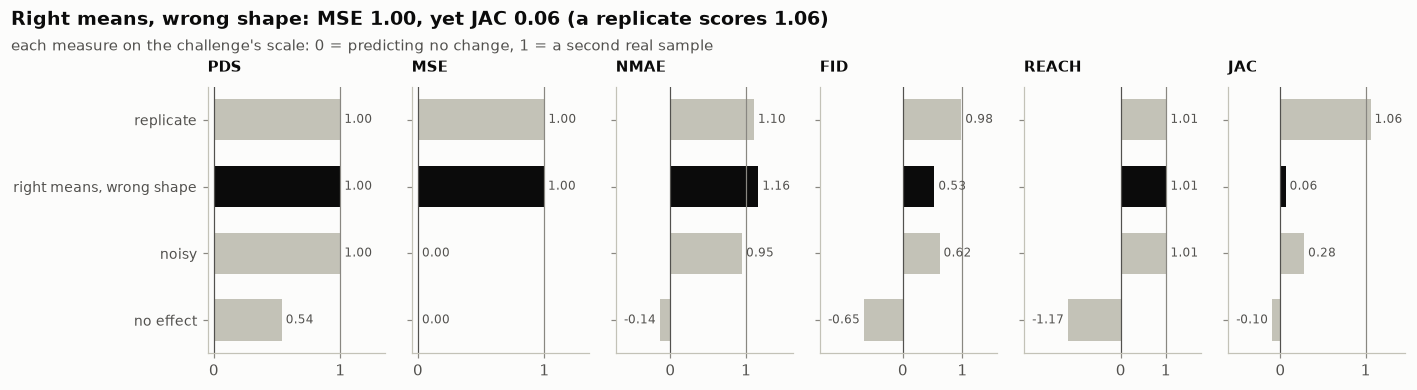

In [13]:
# The figure: the six measures of each prediction.
if GPU:
    no_spread, replicate = toy_scores["right means, wrong shape"], toy_scores["replicate"]
    finding = (
        f"Right means, wrong shape: MSE {no_spread['mse']:.2f}, yet JAC {no_spread['jac']:.2f} "
        f"(a replicate scores {replicate['jac']:.2f})"
    )
    fig = plot_toy_scores(toy_scores, KINDS, finding)

In [14]:
# One knockdown through the scorer's rank test, in each prediction's cells.
toy_controls = toy_real[toy_real.obs["target_gene"] == "non-targeting"].X
toy_ranks = ControlRanks(toy_controls, mean_cpm(toy_controls) > 5)  # vs the real controls
example_kd = toy_knockdowns[1]
truly_changed = true_lfc[example_kd] != 0
called_level = 0.05 / N_GENES  # roughly where the test starts calling a gene


def through_rank_test(cells):
    """The example knockdown's log2 fold change and rank-test p-value per gene, in some cells."""
    kd = cells[cells.obs["target_gene"] == example_kd].X
    z = toy_ranks.z(kd)
    lfc = np.log2(np.maximum(mean_cpm(kd), 1e-3) / np.maximum(mean_cpm(toy_controls), 1e-3))
    return lfc, 2 * norm.sf(np.abs(z))


volcano = {kind: through_rank_test(cells) for kind, cells in toy_predictions.items()}
called_wrongly = {kind: (p < called_level) & ~truly_changed for kind, (_, p) in volcano.items()}
false_hits = {kind: int(called.sum()) for kind, called in called_wrongly.items()}

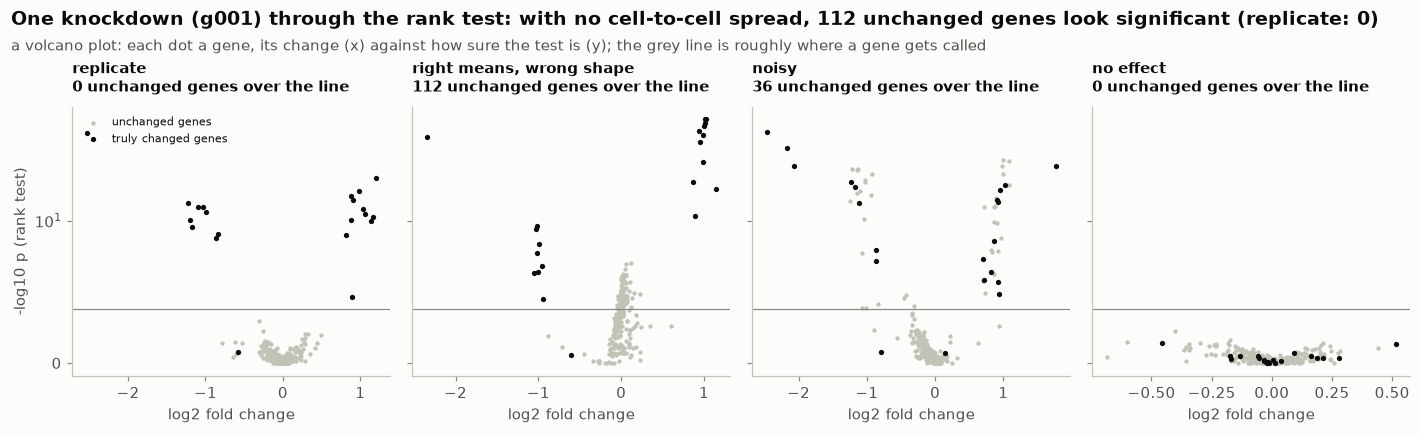

In [15]:
# The figure: one volcano plot per prediction.
finding = (
    f"One knockdown ({example_kd}) through the rank test: with no cell-to-cell spread, "
    f"{false_hits['right means, wrong shape']} unchanged genes look significant "
    f"(replicate: {false_hits['replicate']})"
)
fig = plot_volcanoes(volcano, truly_changed, false_hits, called_level, finding)

In [16]:
# What we learned, in this run's numbers.
if GPU:
    mse, jac, replicate_jac = no_spread["mse"], no_spread["jac"], replicate["jac"]
    print(
        "What we learned: a prediction with the right means but no cell-to-cell spread keeps MSE "
        f"at {mse:.2f} yet scores JAC {jac:.2f} (a replicate: {replicate_jac:.2f}); the rank test "
        "calls genes that did not change."
    )
    EVIDENCE[2] = f"right means, wrong shape: MSE {mse:.2f} but JAC {jac:.2f}"

What we learned: a prediction with the right means but no cell-to-cell spread keeps MSE at 1.00 yet scores JAC 0.06 (a replicate: 1.06); the rank test calls genes that did not change.


**The playbook lesson.** Build the scorer's intuition before the model: a metric is a program you can test on cases you construct.

## 3. Meet the final lines

**The question.** The final round's three lines arrive unnamed, as control cells only. What are they? A
model that knows which public screens resemble the test line can weight them; so before modelling, we use
the unlabelled test data to identify the test distribution.

**The experiment.** (a) A map of the three lines' control cells: a random 3,000 cells per line, each scaled to the
same total and log-transformed, then drawn in 2-D with UMAP (a layout that places cells with similar profiles near
each other; distances between islands are only roughly meaningful). (b) How alike the lines are: the correlation of
their pooled expression profiles. (c) "Who are you?": each line's pooled profile ranked against DepMap, a public
catalogue of ~1,500 cancer cell lines whose expression has been measured, by Spearman correlation (correlation of
ranks) over the 2,000 genes that vary most between catalogue lines. The catalogue labels each line with its
lineage: "Myeloid" is a blood cancer of the bone marrow's myeloid cells (acute myeloid leukaemia, AML), "CNS/Brain"
a brain tumour (U-87 MG is a glioblastoma line).

In [17]:
# The code this section is about (from the package):
show(match_lines)

def match_lines(ctrl_sum: np.ndarray, genes: list, dm: pd.DataFrame, n_top: int = 2000) -> pd.Series:
    """Spearman of a line's pooled controls (log2 CPM + 1) with every DepMap line, over the 2,000 genes that vary
    most across DepMap."""
    from scipy.stats import rankdata

    prof = pd.Series(np.log2(ctrl_sum / ctrl_sum.sum() * 1e6 + 1), index=genes)
    shared = dm.columns.intersection(prof.index)
    top = dm[shared].std(0).sort_values(ascending=False).index[:n_top]
    q = rankdata(prof[top].to_numpy())
    M = np.apply_along_axis(rankdata, 1, dm[top].to_numpy())
    q = (q - q.mean()) / q.std()
    M = (M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)
    return pd.Series(M @ q / len(q), index=dm.index).sort_values(ascending=False)

In [18]:
# The three lines' control cells, and each line's pooled profile (all its control cells added up).
import scanpy as sc

line_colour = line_colours(contexts)  # D, E and F keep these colours in every figure
final_controls = {c: read_controls(PHASE, c, final_genes, manifest) for c in contexts}


def pooled_counts(cells):
    """All of an AnnData's cells added up: the summed counts of each gene."""
    return np.asarray(cells.X.sum(axis=0, dtype=np.float64)).ravel()


pooled = {c: pooled_counts(final_controls[c]) for c in contexts}

In [19]:
# (a) The map: 3,000 random controls per line, scaled to the same total, logged, laid out by UMAP.
sample_rng = np.random.default_rng(0)


def random_controls(c, n_cells=3000):
    """n_cells control cells of line c, drawn at random (kept in file order)."""
    cells = final_controls[c]
    return cells[np.sort(sample_rng.choice(cells.n_obs, n_cells, replace=False))]


umap_cells = ad.concat([random_controls(c) for c in contexts])
umap_cells.obs["line"] = umap_cells.obs["context"].astype(str)
sc.pp.normalize_total(umap_cells, target_sum=1e4)
sc.pp.log1p(umap_cells)
sc.pp.highly_variable_genes(umap_cells, n_top_genes=2000)
sc.pp.pca(umap_cells, n_comps=50, mask_var="highly_variable", random_state=0)
sc.pp.neighbors(umap_cells, random_state=0)
sc.tl.umap(umap_cells, random_state=0)

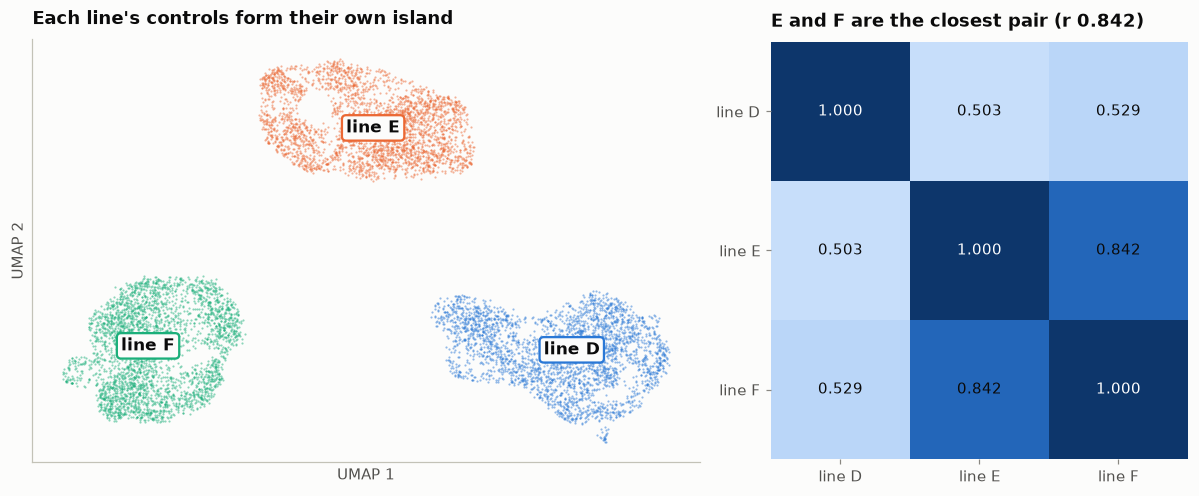

In [20]:
# (b) How alike the lines are: the correlation of their pooled log CPM over expressed genes.
def log_cpm(counts):
    """log2 (CPM + 1) of a pooled profile."""
    return np.log2(counts / counts.sum() * 1e6 + 1)


line_profiles = pd.DataFrame({c: log_cpm(pooled[c]) for c in contexts}, index=final_genes)
line_corr = line_profiles[(line_profiles > 1).any(axis=1)].corr()
pair_list = [(a, b) for i, a in enumerate(contexts) for b in contexts[i + 1 :]]
closest = max((line_corr.loc[a, b], a, b) for a, b in pair_list)  # (r, line, line)
umap_xy = umap_cells.obsm["X_umap"]
fig = plot_line_map(umap_xy, umap_cells.obs["line"], contexts, line_colour, line_corr, closest)

In [21]:
# (c) Who are you? Each line's pooled profile ranked against DepMap's ~1,500 cancer lines.
has_depmap = (TABLES / "depmap_expression.csv").exists()
if has_depmap:
    depmap_files = [TABLES / f for f in ("depmap_expression.csv", "depmap_models.csv", "hgnc.txt")]
    depmap, depmap_name, depmap_lineage = depmap_profiles(*depmap_files, final_genes)
    matches = {c: match_lines(pooled[c], final_genes, depmap) for c in contexts}


def verdict(match):
    """The best match and its lineage, if four of the five best share that lineage."""
    lineages = pd.Series([depmap_lineage[m] for m in match.index[:5]]).value_counts()
    if lineages.iloc[0] >= 4 and lineages.index[0] != "?":
        return f"{depmap_name[match.index[0]]} ({lineages.index[0]})"
    return "no clear match"

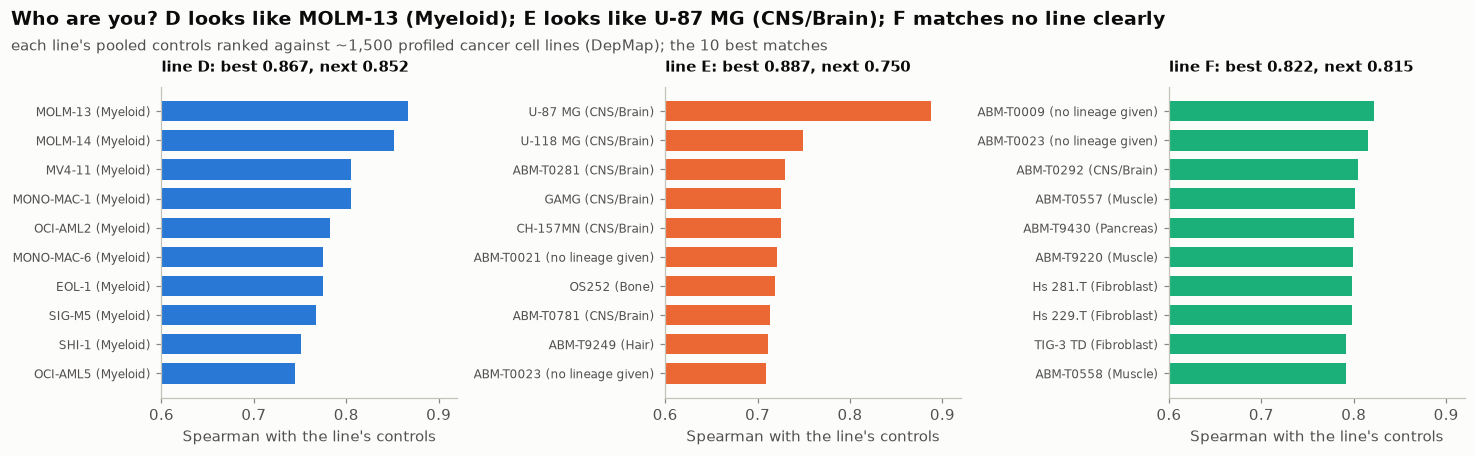

In [22]:
# The figure: each line's 10 best matches in the catalogue.
if has_depmap:
    verdicts = {c: verdict(m) for c, m in matches.items()}
    looks_like = [
        f"{c} looks like {v}" if v != "no clear match" else f"{c} matches no line clearly"
        for c, v in verdicts.items()
    ]
    finding = "Who are you? " + "; ".join(looks_like)
    fig = plot_line_matches(matches, depmap_name, depmap_lineage, line_colour, finding)

In [23]:
# The five best matches of each line, as numbers.
def top_five(match):
    """The five best matches: (name, lineage, rho)."""
    return [(depmap_name[x], depmap_lineage[x], round(float(match[x]), 3)) for x in match.index[:5]]


if has_depmap:
    print("\n".join(f"{c} {top_five(m)}" for c, m in matches.items()))

D [('MOLM-13', 'Myeloid', 0.867), ('MOLM-14', 'Myeloid', 0.852), ('MV4-11', 'Myeloid', 0.805), ('MONO-MAC-1', 'Myeloid', 0.805), ('OCI-AML2', 'Myeloid', 0.783)]
E [('U-87 MG', 'CNS/Brain', 0.887), ('U-118 MG', 'CNS/Brain', 0.75), ('ABM-T0281', 'CNS/Brain', 0.73), ('GAMG', 'CNS/Brain', 0.725), ('CH-157MN', 'CNS/Brain', 0.725)]
F [('ABM-T0009', '?', 0.822), ('ABM-T0023', '?', 0.815), ('ABM-T0292', 'CNS/Brain', 0.804), ('ABM-T0557', 'Muscle', 0.801), ('ABM-T9430', 'Pancreas', 0.8)]


In [24]:
# What we learned, in this run's numbers.
r_closest, line_a, line_b = closest
if has_depmap:
    best_matches = [
        f"line {c} matches {depmap_name[m.index[0]]} best (rho {m.iloc[0]:.3f})"
        for c, m in matches.items()
    ]
    closest_pair = f"lines {line_a} and {line_b} are the closest pair (r {r_closest:.3f})"
    print(f"What we learned: {closest_pair}; " + "; ".join(best_matches))
    EVIDENCE[3] = "; ".join(f"{c}: {v}" for c, v in verdicts.items())
else:
    print(f"lines {line_a} and {line_b} are the closest pair")

What we learned: lines E and F are the closest pair (r 0.842); line D matches MOLM-13 best (rho 0.867); line E matches U-87 MG best (rho 0.887); line F matches ABM-T0009 best (rho 0.822)


**What it means for the model.** D is a blood-cancer line, and blood lines (K562, Jurkat) are the best-screened
cells in the public data. E is a brain tumour line and F is not identified (its best matches are mixed: catalogue
models without a lineage label, then brain, muscle, pancreas and fibroblast lines, all close together); E and F are each other's closest relatives, so the pipeline
should predict them alike (section 13 checks it). No public screen of a brain line covers the panel.

**The playbook lesson.** Identify your test distribution with the unlabelled data you are given.

## 4. The training screens

**The question.** What public perturbation data exists for the final panel, in which cell types, and how
deep is it? A model can only borrow what was measured.

**The experiment.** For each public screen (a source table), which of the final panel's 300 knockdowns it
measured; how many cells sit behind each measured knockdown; how many molecules each cell carries,
against the final lines' own controls.

In [25]:
# The code this section is about (from the package):
show(source_table)

def source_table(srcs: Sources, name: str, keys: list, gidx: dict) -> dict:
    """One source restricted to `keys`: its clipped rows and their variances (NaN = absent), and three
    per-gene summaries over ALL its rows: the mean with each gene's own knockdown left out (`cmean`, the
    centring), the plain mean (`generic`, the shift any knockdown causes) and mean(l^2 - se^2) (`tpart`,
    the signal variance used by the empirical-Bayes shrinkage)."""
    s = srcs.load(name)
    L = np.clip(s["lfc"], -CLIP, CLIP)
    if name.startswith("jiang_"):  # small pathway screens: a flat variance
        V = np.where(np.isfinite(L), np.float32(0.35**2), np.nan).astype(np.float32)
    else:
        V = srcs.se2(name, s)
    idx = {t: i for i, t in enumerate(s["target"])}
    r = np.array([idx.get(k, -1) for k in keys])
    rows = np.full((len(keys), L.shape[1]), np.nan, np.float32)
    se2 = np.full_like(rows, np.nan)
    rows[r >= 0] = L[r[r >= 0]]
    se2[r >= 0] = V[r[r >= 0]]
    cmean = own_out_mean(L, s["target"], gidx)
    generic = np.nan_to_num(np.nanmean(L, axis=0)).astype(np.float32)
    okv = np.isfinite(V)
    tterm = np.where(okv, L.astype(np.float64) ** 2 - V, 0.0).sum(0)
    tcnt = okv.sum(0)
    tpart = np.where(tcnt > 0, tterm / np.maximum(tcnt, 1), 0.0).astype(np.float32)
    present = r >= 0
    return {
        "type": s["cell_type"],
        "chem": s["chem"],
        "present": present,
        "rows": rows[present] if present.any() else None,
        "se2": se2[present] if present.any() else None,
        "cmean": cmean,
        "generic": generic,
        "tpart": tpart,
    }

In [26]:
# Which panel knockdowns each public screen measured, and the cells behind each measured one.
def screen_coverage(name):
    """One screen's (bool per panel knockdown: measured, median cells per measured knockdown)."""
    table = np.load(TABLES / f"{name}.npz", allow_pickle=True)
    row = {g: i for i, g in enumerate(table["target"].astype(str))}
    measured = np.array([p in row for p in final_panel])
    if not measured.any():
        return measured, 0.0
    n_cells = np.asarray(table["n_cells"], np.float64)
    return measured, float(np.median(n_cells[[row[p] for p in final_panel if p in row]]))


def pathway_coverage():
    """Whether any of the 30 pathway screens (six lines) measured each panel knockdown."""
    targets = set()
    for name in JIANG:
        if (TABLES / f"{name}.npz").exists():
            targets |= set(np.load(TABLES / f"{name}.npz", allow_pickle=True)["target"].astype(str))
    return np.array([p in targets for p in final_panel])

In [27]:
# Every screen this mode holds, then the pathway screens as one row.
single_screens = [n for n in FINAL_SOURCES if not n.startswith("jiang_")]
available = [n for n in single_screens if (TABLES / f"{n}.npz").exists()]
coverage = {n: screen_coverage(n) for n in available}  # FAST holds a few of the screens
covered = {n: measured for n, (measured, _) in coverage.items()}
cells_per_kd = {n: median for n, (_, median) in coverage.items()}
covered["jiang"] = pathway_coverage()
screen_order = sorted(covered, key=lambda n: -covered[n].sum())  # the most-covering screens first
# how many screens measured each knockdown
n_screens = np.vstack([covered[n] for n in screen_order]).astype(float).sum(0)

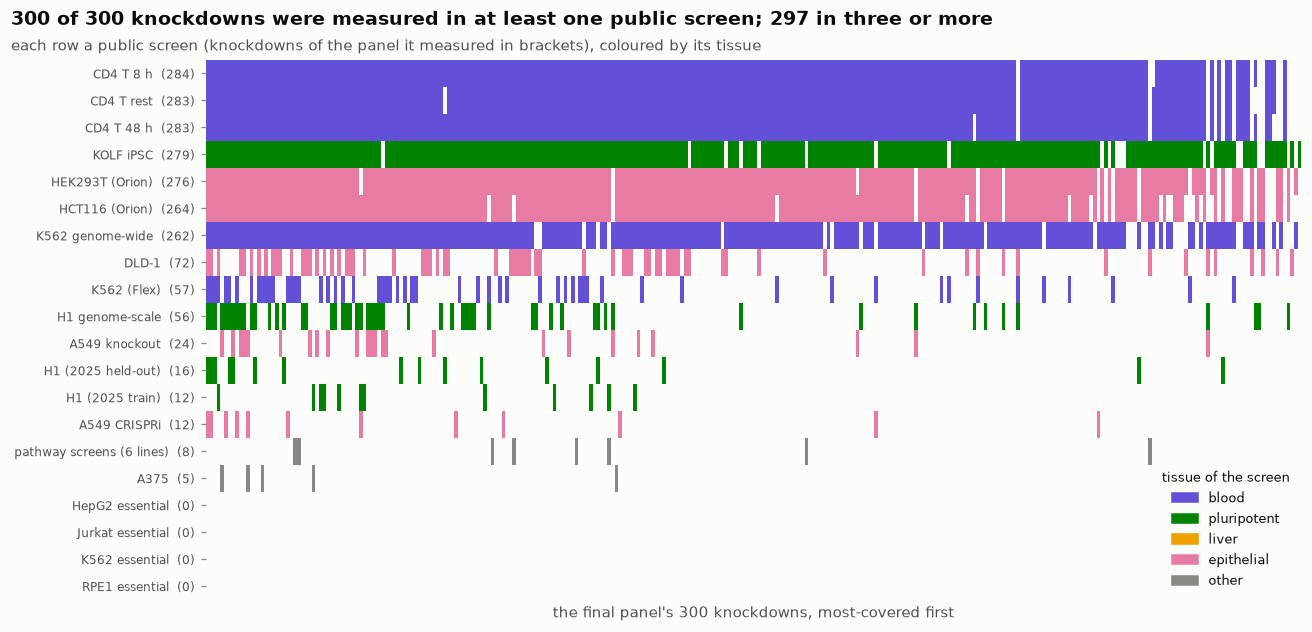

In [28]:
# The figure: which screen measured which knockdown.
n_measured, three_plus = int((n_screens > 0).sum()), int((n_screens >= 3).sum())
finding = (
    f"{n_measured} of {len(final_panel)} knockdowns were measured in at least one public screen; "
    f"{three_plus} in three or more"
)
fig = plot_screen_coverage(covered, screen_order, finding)

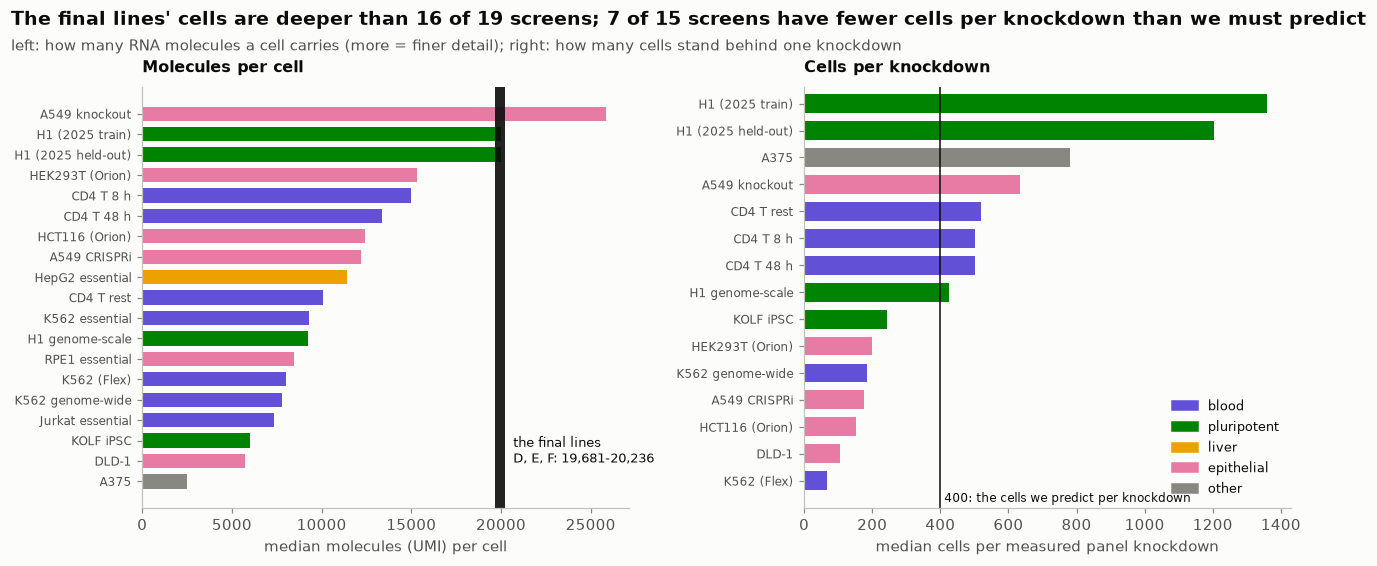

In [29]:
# Molecules per cell of each screen against the final lines, and cells per measured knockdown.
def median_depth(cells):
    """The median molecules (summed counts) per cell."""
    return float(np.median(np.asarray(cells.X.sum(axis=1)).ravel()))


final_depth = {c: median_depth(final_controls[c]) for c in contexts}
single_cell = [n for n in screen_order if n != "jiang"]
with_panel = [n for n in single_cell if covered[n].any()]
deeper = sum(DEPTH.get(n, 8000) < min(final_depth.values()) for n in single_cell)
few = sum(cells_per_kd[n] < 400 for n in with_panel)
finding = (
    f"The final lines' cells are deeper than {deeper} of {len(single_cell)} screens; {few} of "
    f"{len(with_panel)} screens have fewer cells per knockdown than we must predict"
)
fig = plot_depth_and_cells(single_cell, covered, cells_per_kd, final_depth, finding)

In [30]:
# What we learned, in this run's numbers.
depth_range = f"{min(final_depth.values()):,.0f}-{max(final_depth.values()):,.0f}"
print(
    f"What we learned: {n_measured} of {len(final_panel)} panel knockdowns are measured somewhere, "
    f"{three_plus} in three or more screens; the final lines carry a median {depth_range} "
    "molecules per cell."
)
measured_somewhere = f"{n_measured} of {len(final_panel)} knockdowns measured somewhere"
EVIDENCE[4] = f"{measured_somewhere}; no screen of a brain line"

What we learned: 300 of 300 panel knockdowns are measured somewhere, 297 in three or more screens; the final lines carry a median 19,681-20,236 molecules per cell.


**The playbook lesson.** Inventory the data before choosing a model; data, not architecture, is usually the bottleneck.

## 5. How much of a measured effect is signal?

**The question.** A screen reports one knockdown's effect as a log2 fold change per gene, from a few hundred
cells. How much of that profile would a second, independent set of cells reproduce?

**The experiment.** Each knockdown's cells split at random into two halves; each half gives its own profile
against the screen's controls. The correlation of the two halves over well-expressed genes (control CPM > 20),
stepped up to the full sample (Spearman-Brown, 2r / (1 + r)), is the profile's reliability: the share of its
variance that is repeatable.

In [31]:
# Each knockdown's split-half reliability, in the six lines whose cells were split (FAST: no KOLF).
def split_half_reliability(halves_file) -> np.ndarray:
    """Per knockdown: the correlation of its two halves' profiles over genes at control CPM > 20,
    stepped up to the full sample (Spearman-Brown); NaN with 100 genes or fewer to compare."""
    well = halves_file["ctrl_cpm"][0] > 20
    half_a = halves_file["lfc_a"][:, well].astype(np.float64)
    half_b = halves_file["lfc_b"][:, well].astype(np.float64)
    ok = np.isfinite(half_a) & np.isfinite(half_b)
    rel = np.full(len(half_a), np.nan)
    for i in range(len(half_a)):
        m = ok[i]
        if m.sum() > 100:
            r = np.corrcoef(half_a[i, m], half_b[i, m])[0, 1]
            rel[i] = 2 * r / (1 + r) if r > -1 else np.nan
    return rel

In [32]:
# The six lines' halves files, and every knockdown's reliability.
half_lines = [n for n in HALF_LINE_LABEL if (TABLES / "halves" / f"{n}.npz").exists()]
halves = {n: np.load(TABLES / "halves" / f"{n}.npz", allow_pickle=True) for n in half_lines}
reliability = {n: split_half_reliability(halves[n]) for n in half_lines}
median_rel = {n: float(np.nanmedian(r)) for n, r in reliability.items()}
report = [
    f"{HALF_LINE_LABEL[n]:>10}: {np.isfinite(r).sum():5d} knockdowns, "
    f"median reliability {np.nanmedian(r):.2f}"
    for n, r in reliability.items()
]
print("\n".join(report))

      K562:  1832 knockdowns, median reliability 0.24
    Jurkat:  1815 knockdowns, median reliability 0.22
     HepG2:  1061 knockdowns, median reliability 0.38
      RPE1:  1611 knockdowns, median reliability 0.43
 H1 (Flex):   148 knockdowns, median reliability 0.90
 KOLF iPSC: 10922 knockdowns, median reliability 0.22


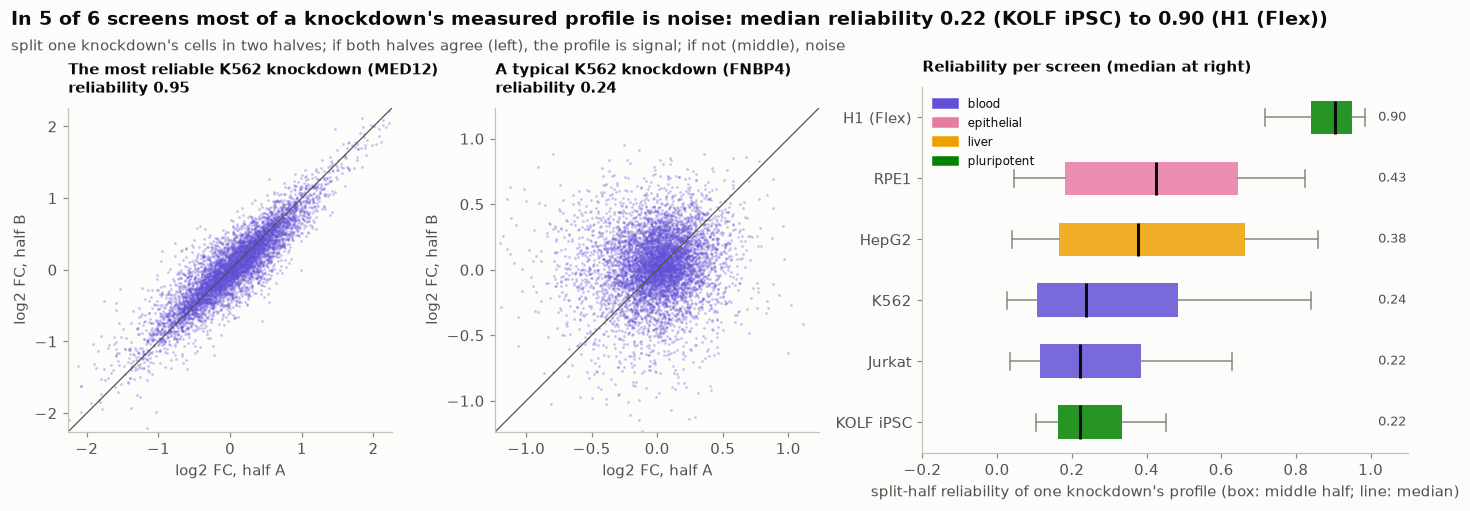

In [33]:
# Two K562 knockdowns to look at: the most reliable one, and the one nearest the median.
k562_rel = reliability["bench_k562"]
finite = np.flatnonzero(np.isfinite(k562_rel))
strong = int(np.nanargmax(k562_rel))
weak = int(finite[np.argmin(np.abs(k562_rel[finite] - np.nanmedian(k562_rel)))])
lowest, highest = min(median_rel, key=median_rel.get), max(median_rel, key=median_rel.get)
n_low = sum(v < 0.5 for v in median_rel.values())
finding = (
    f"In {n_low} of {len(median_rel)} screens most of a knockdown's measured profile is noise: "
    f"median reliability {median_rel[lowest]:.2f} ({HALF_LINE_LABEL[lowest]}) to "
    f"{median_rel[highest]:.2f} ({HALF_LINE_LABEL[highest]})"
)
fig = plot_reliability(halves["bench_k562"], reliability, strong, weak, finding)

In [34]:
# What we learned, in this run's numbers.
rel_text = ", ".join(f"{HALF_LINE_LABEL[n]} {v:.2f}" for n, v in median_rel.items())
print(f"What we learned: median split-half reliability of one knockdown's profile is {rel_text}.")
EVIDENCE[5] = "median reliability " + rel_text

What we learned: median split-half reliability of one knockdown's profile is K562 0.24, Jurkat 0.22, HepG2 0.38, RPE1 0.43, H1 (Flex) 0.90, KOLF iPSC 0.22.


**The playbook lesson.** Measure the noise ceiling before you measure a model.

## 6. Do effects transfer between cell lines?

**The question.** The final lines were never perturbed, so every prediction borrows another line's
measurements. When the same gene is knocked down in two lines, how alike are the two responses, once the
noise of section 5 is accounted for?

**The experiment.** For each pair of lines and each knockdown both measured (both reliabilities above 0.2):
the correlation of the two full profiles over genes well expressed in both, divided by sqrt(reliability A x
reliability B), which is what the correlation would be with noise-free profiles. Then a second comparison:
for the same knockdown in line B, is line A's profile of that gene a better guess than line A's average
response to any knockdown?

In [35]:
# Each line's full profiles of the knockdowns it measured reliably (reliability above 0.2).
transfer_lines = [n for n in HALF_LINE_TABLE if n in halves]
transfer_tables = open_tables(TABLES, [HALF_LINE_TABLE[n] for n in transfer_lines])
kd_reliability = {
    n: dict(zip(halves[n]["target"].astype(str), reliability[n])) for n in transfer_lines
}


def reliable_profiles(line):
    """{knockdown: its full log2 profile} for the line's knockdowns with a reliability above 0.2."""
    table, rel = transfer_tables.load(HALF_LINE_TABLE[line]), kd_reliability[line]
    rows = enumerate(table["target"])
    return {p: table["lfc"][i] for i, p in rows if np.isfinite(rel.get(p, np.nan)) and rel[p] > 0.2}


profiles = {n: reliable_profiles(n) for n in transfer_lines}
control_cpm = {n: halves[n]["ctrl_cpm"][0] for n in transfer_lines}

In [36]:
# For each ordered pair of lines (A, B), over the knockdowns both measured: the noise-corrected
# correlation of A's and B's profiles, and how often A's average response is the better guess.
def compare_lines(line_a, line_b):
    """(median noise-corrected r, share of knockdowns where A's average response beats its own
    profile, knockdowns shared), or None when the lines share fewer than 20 knockdowns."""
    well = (control_cpm[line_a] > 20) & (control_cpm[line_b] > 20)
    shared = sorted(set(profiles[line_a]) & set(profiles[line_b]))
    if len(shared) < 20:
        return None
    prof_a = np.vstack([profiles[line_a][p] for p in shared])[:, well].astype(np.float64)
    prof_b = np.vstack([profiles[line_b][p] for p in shared])[:, well].astype(np.float64)
    ok = np.isfinite(prof_a).all(0) & np.isfinite(prof_b).all(0)
    prof_a, prof_b = prof_a[:, ok], prof_b[:, ok]
    n = len(shared)
    r_own = np.array([np.corrcoef(prof_a[k], prof_b[k])[0, 1] for k in range(n)])
    noise = np.sqrt([kd_reliability[line_a][p] * kd_reliability[line_b][p] for p in shared])
    avg = prof_a.mean(0)  # A's average response; below, leaving out the knockdown itself
    leave_one_out = [(avg * n - prof_a[k]) / (n - 1) for k in range(n)]
    r_avg = np.array([np.corrcoef(leave_one_out[k], prof_b[k])[0, 1] for k in range(n)])
    return float(np.median(r_own / noise)), float(np.mean(r_avg > r_own)), n

In [37]:
# Every ordered pair of lines, one printed line each.
def transfer_matrix():
    """The corrected r of every ordered pair (NaN where not compared), and
    {(A, B): (share, knockdowns)}; prints one line per pair."""
    corrected = np.full((len(transfer_lines), len(transfer_lines)), np.nan)
    own_vs_avg = {}
    for i, a in enumerate(transfer_lines):
        for j, b in enumerate(transfer_lines):
            result = compare_lines(a, b) if i != j else None
            if result is None:
                continue
            corrected[i, j], share, n_shared = result
            own_vs_avg[(a, b)] = (share, n_shared)
            label = f"{HALF_LINE_LABEL[a]:>10} -> {HALF_LINE_LABEL[b]:<10}"
            print(
                f"{label} {n_shared:4d} shared, corrected r {corrected[i, j]:.2f}, "
                f"average beats own in {share:.0%}"
            )
    return corrected, own_vs_avg


corrected_r, own_vs_avg = transfer_matrix()

      K562 -> Jurkat      564 shared, corrected r 0.65, average beats own in 35%
      K562 -> HepG2       489 shared, corrected r 0.48, average beats own in 49%


      K562 -> RPE1        552 shared, corrected r 0.45, average beats own in 68%
      K562 -> H1 (Flex)    22 shared, corrected r 0.53, average beats own in 5%
      K562 -> KOLF iPSC   230 shared, corrected r 0.19, average beats own in 73%
    Jurkat -> K562        564 shared, corrected r 0.65, average beats own in 18%


    Jurkat -> HepG2       510 shared, corrected r 0.47, average beats own in 46%
    Jurkat -> RPE1        657 shared, corrected r 0.49, average beats own in 53%
    Jurkat -> H1 (Flex)    21 shared, corrected r 0.41, average beats own in 0%


    Jurkat -> KOLF iPSC   303 shared, corrected r 0.17, average beats own in 69%
     HepG2 -> K562        489 shared, corrected r 0.48, average beats own in 13%
     HepG2 -> Jurkat      510 shared, corrected r 0.47, average beats own in 33%


     HepG2 -> RPE1        511 shared, corrected r 0.68, average beats own in 78%
     HepG2 -> KOLF iPSC   175 shared, corrected r 0.16, average beats own in 61%
      RPE1 -> K562        552 shared, corrected r 0.45, average beats own in 14%


      RPE1 -> Jurkat      657 shared, corrected r 0.49, average beats own in 18%
      RPE1 -> HepG2       511 shared, corrected r 0.68, average beats own in 42%
      RPE1 -> H1 (Flex)    33 shared, corrected r 0.33, average beats own in 3%
      RPE1 -> KOLF iPSC   385 shared, corrected r 0.18, average beats own in 57%
 H1 (Flex) -> K562         22 shared, corrected r 0.53, average beats own in 9%
 H1 (Flex) -> Jurkat       21 shared, corrected r 0.41, average beats own in 10%
 H1 (Flex) -> RPE1         33 shared, corrected r 0.33, average beats own in 18%


 H1 (Flex) -> KOLF iPSC    87 shared, corrected r 0.21, average beats own in 39%
 KOLF iPSC -> K562        230 shared, corrected r 0.19, average beats own in 59%
 KOLF iPSC -> Jurkat      303 shared, corrected r 0.17, average beats own in 64%
 KOLF iPSC -> HepG2       175 shared, corrected r 0.16, average beats own in 63%
 KOLF iPSC -> RPE1        385 shared, corrected r 0.18, average beats own in 59%
 KOLF iPSC -> H1 (Flex)    87 shared, corrected r 0.21, average beats own in 16%


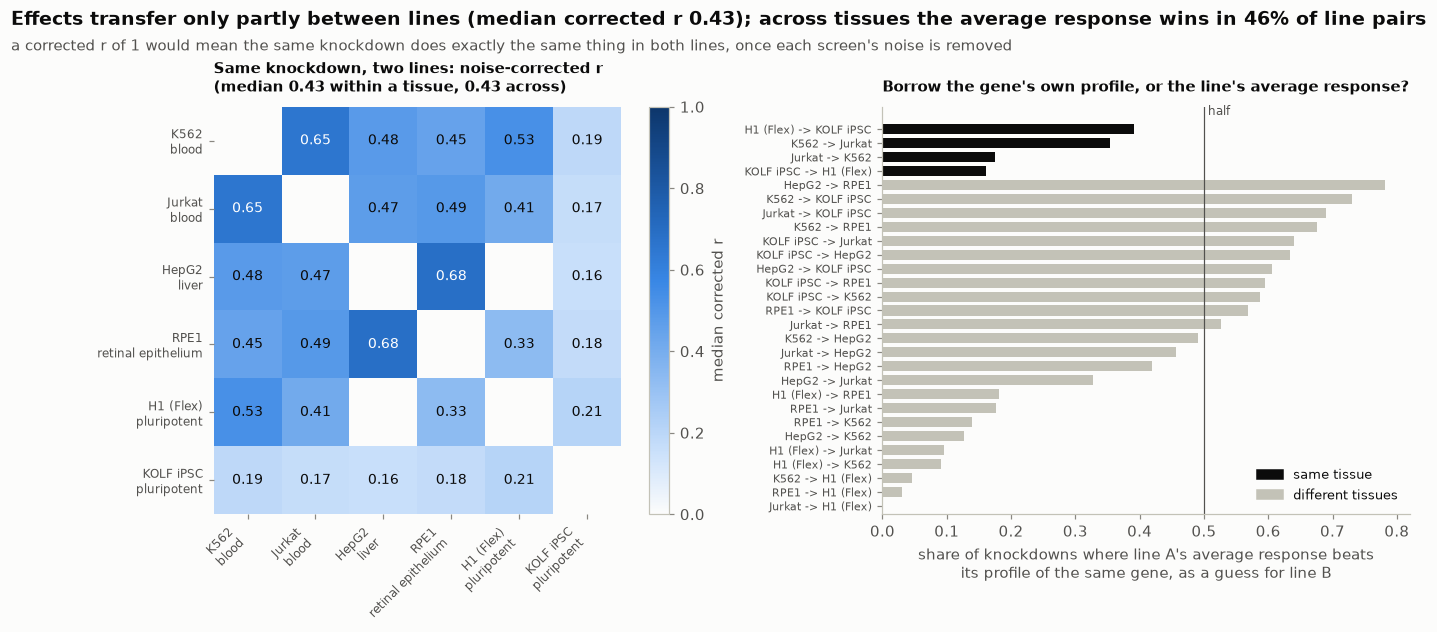

In [38]:
# Where only one direction of a pair was compared, use it for both; then split pairs by tissue.
transfer = np.where(np.isnan(corrected_r), 0.5 * (corrected_r + corrected_r.T), corrected_r)
tissue = [HALF_LINE_TISSUE[n] for n in transfer_lines]
n_half = len(tissue)
compared_pairs = [(i, j) for i in range(n_half) for j in range(n_half) if i != j]
compared_pairs = [(i, j) for i, j in compared_pairs if np.isfinite(transfer[i, j])]
within = [transfer[i, j] for i, j in compared_pairs if tissue[i] == tissue[j]]
across = [transfer[i, j] for i, j in compared_pairs if tissue[i] != tissue[j]]
tissue_of = HALF_LINE_TISSUE
across_pairs = {(a, b): v for (a, b), v in own_vs_avg.items() if tissue_of[a] != tissue_of[b]}
across_wins = [share > 0.5 for share, _ in across_pairs.values()]
average_wins = np.mean(across_wins)
overall_r = np.median(transfer[np.isfinite(transfer) & ~np.eye(n_half, dtype=bool)])
finding = (
    f"Effects transfer only partly between lines (median corrected r {overall_r:.2f}); "
    f"across tissues the average response wins in {average_wins:.0%} of line pairs"
)
within_median, across_median = np.median(within), np.median(across)
fig = plot_transfer(transfer, transfer_lines, own_vs_avg, within_median, across_median, finding)

In [39]:
# What we learned, in this run's numbers.
print(
    f"What we learned: noise-corrected transfer has median {within_median:.2f} within a tissue and "
    f"{across_median:.2f} across; across tissues the average response beats the gene's own profile "
    f"in {average_wins:.0%} of line pairs."
)
EVIDENCE[6] = (
    f"noise-corrected transfer {within_median:.2f} within a tissue, {across_median:.2f} across"
)

What we learned: noise-corrected transfer has median 0.43 within a tissue and 0.43 across; across tissues the average response beats the gene's own profile in 46% of line pairs.


**The two modes disagree here, and that is the finding.** On FAST's small subset (a few dozen knockdowns shared
per pair of lines, 100 cells each), transfer looks stronger within a tissue than across tissues: 0.63 against 0.45
in our FAST run (quoted from that run). The full data says the two are about equal: 0.43 against 0.43 in the FULL
run saved with this notebook. A pattern read off a few dozen knockdowns can vanish at full scale.

**The playbook lesson.** Measure how well effects transfer, on all the data you have, before deciding how to
weight the sources: a small subset can show a pattern the full data does not.

## 7. A dead end worth seeing: do resting cells reveal knockdown effects?

**The question.** Even unperturbed cells vary: some happen to express a gene X less than others. If cells
with naturally low X also showed X's knockdown signature, the controls alone (which is all we get for the
final lines) would predict each knockdown in that very line.

**The experiment.** In K562's controls (library size, a cell's total count, regressed out, then also the controls' 10 strongest shared
axes of variation), each gene's covariance with X across
cells, sign-flipped, is a predicted profile for knocking X down. It is compared with X's measured knockdown
profile, for knockdowns with at least 100 cells, a reliability above 0.2 and X expressed at CPM > 20. Two
checks keep it honest: a positive control, where the "knockdown" is a fluctuation by construction (the
control cells in the lowest decile of X, from a separate half of the controls), and a negative control (a
random gene's covariance).

In [40]:
# K562's essential-gene screen: its control cells, and every knockdown's cells.
k562 = ad.read_h5ad(TABLES / "bench" / "k562" / "reference.h5ad")
k562_labels = k562.obs["target_gene"].astype(str).to_numpy()
k562_counts = sp.csr_matrix(k562.X)
k562_gene_index = {g: i for i, g in enumerate(k562.var_names.astype(str))}
k562_controls = k562_counts[k562_labels == "non-targeting"]
library_size = np.asarray(k562_controls.sum(1)).ravel()  # each control cell's total count
k562_cpm = mean_cpm(k562_controls)

In [41]:
# The genes compared (CPM > 20), and the knockdowns tested: at least 100 cells, a reliability
# above 0.2, and a target the controls express (CPM > 20), so its fluctuation can be seen.
compared = np.flatnonzero(k562_cpm > 20)
k562_reliability = dict(zip(halves["bench_k562"]["target"].astype(str), reliability["bench_k562"]))


def testable(p):
    """Whether knockdown p qualifies for the test."""
    expressed = p in k562_gene_index and k562_cpm[k562_gene_index[p]] > 20
    return expressed and (k562_labels == p).sum() >= 100 and k562_reliability.get(p, 0) > 0.2


tested = [p for p in sorted(set(k562_labels) - {"non-targeting"}) if testable(p)]
targets = np.array([k562_gene_index[p] for p in tested])  # each tested knockdown's target gene

In [42]:
# Each gene relative to its mean, in CPM. The controls split at random: half A gives the
# covariances, half B the planted fluctuation.
split_rng = np.random.default_rng(0)
in_half_a = split_rng.random(k562_controls.shape[0]) < 0.5
used = np.union1d(compared, targets)
col = {g: i for i, g in enumerate(used)}  # gene index -> column of the matrices below
compared_cols = np.array([col[g] for g in compared])
cpm = np.asarray(k562_controls[:, used].todense(), np.float64) / library_size[:, None] * 1e6
gene_mean = cpm.mean(0)
relative = cpm / np.where(gene_mean > 0, gene_mean, 1.0)
library_terms = np.column_stack([np.ones(len(library_size)), np.log(library_size)])

In [43]:
# Regress out the library size; then each target's covariance with every gene, in half A.
def regress_out(M, covariates):
    """M with its least-squares fit on the covariates removed."""
    return M - covariates @ np.linalg.lstsq(covariates, M, rcond=None)[0]


def half_a_covariances(resid):
    """Half A's centred residuals, and each target's covariance with every compared gene in them."""
    centred = resid[in_half_a] - resid[in_half_a].mean(0)
    n = in_half_a.sum() - 1
    beta = np.vstack([(centred[:, col[x]] @ centred[:, compared_cols]) / n for x in targets])
    return centred, beta


resid_lib = regress_out(relative, library_terms)  # library size regressed out
centred_lib, beta_lib = half_a_covariances(resid_lib)

In [44]:
# The answers to compare with. Planted: half B's cells lowest in X (its bottom decile), a
# "knockdown" that is a fluctuation by construction. Measured: X's real knockdown profile.
relative_b, resid_b = relative[~in_half_a], resid_lib[~in_half_a]
half_b_mean = relative_b[:, compared_cols].mean(0)
base_b = np.where(half_b_mean > 0, half_b_mean, 1.0)


def planted_profile(x):
    """The log2 profile of half B's cells lowest in target x."""
    level = resid_b[:, col[x]]
    lowest = relative_b[level <= np.quantile(level, 0.1)]
    return np.log2(np.maximum(lowest[:, compared_cols].mean(0), 1e-12) / base_b)


def measured_profile(p):
    """Knockdown p's measured log2 profile over the compared genes."""
    kd_cpm = mean_cpm(k562_counts[k562_labels == p])[compared]
    return np.log2(np.maximum(kd_cpm, 1e-12) / np.maximum(k562_cpm[compared], 1e-12))


planted = np.vstack([planted_profile(x) for x in targets])
measured = np.vstack([measured_profile(p) for p in tested])
# the negative control's gene, per knockdown
random_gene = split_rng.choice(len(compared), len(tested))

In [45]:
# The second form of the test: the controls' 10 strongest shared axes (cell cycle, stress, ...)
# regressed out too.
resid_compared = resid_lib[:, compared_cols]
sd = resid_compared.std(0)
sd[sd == 0] = 1.0
standardised = resid_compared / sd
shared_axes = np.linalg.svd(standardised - standardised.mean(0), full_matrices=False)[2][:10]
with_axes = np.column_stack([library_terms, standardised @ shared_axes.T])
centred_axes, beta_axes = half_a_covariances(regress_out(relative, with_axes))

In [46]:
# Knocking X down is predicted as minus X's covariance with each gene. Correlate that with the
# real profile (noise-corrected) and the planted one; and a random gene's with the real one.
def correlations(beta, centred):
    """{"real", "planted", "random": r per tested knockdown} for one form of the test."""
    r = {"real": [], "planted": [], "random": []}
    n = in_half_a.sum() - 1
    for q, x in enumerate(targets):
        keep = compared != x
        pred = -beta[q][keep]
        noise = np.sqrt(k562_reliability[tested[q]])
        r["real"].append(np.corrcoef(pred, measured[q][keep])[0, 1] / noise)
        r["planted"].append(np.corrcoef(pred, planted[q][keep])[0, 1])
        other = (centred[:, compared_cols[random_gene[q]]] @ centred[:, compared_cols]) / n
        r["random"].append(np.corrcoef(-other[keep], measured[q][keep])[0, 1] / noise)
    return {k: np.array(v) for k, v in r.items()}

In [47]:
# Both forms of the test, summarised.
library_only = correlations(beta_lib, centred_lib)
axes_removed = correlations(beta_axes, centred_axes)
shown_as = {"planted": "planted", "real": "real", "random gene": "random"}
median_r = {
    name: f"{np.median(library_only[k]):.2f} / {np.median(axes_removed[k]):.2f}"
    for name, k in shown_as.items()
}
print(
    f"{len(tested)} knockdowns; median r (library only / + 10 shared axes): "
    + ", ".join(f"{name} {v}" for name, v in median_r.items())
)

151 knockdowns; median r (library only / + 10 shared axes): planted 0.06 / 0.01, real -0.00 / -0.01, random gene -0.00 / 0.00


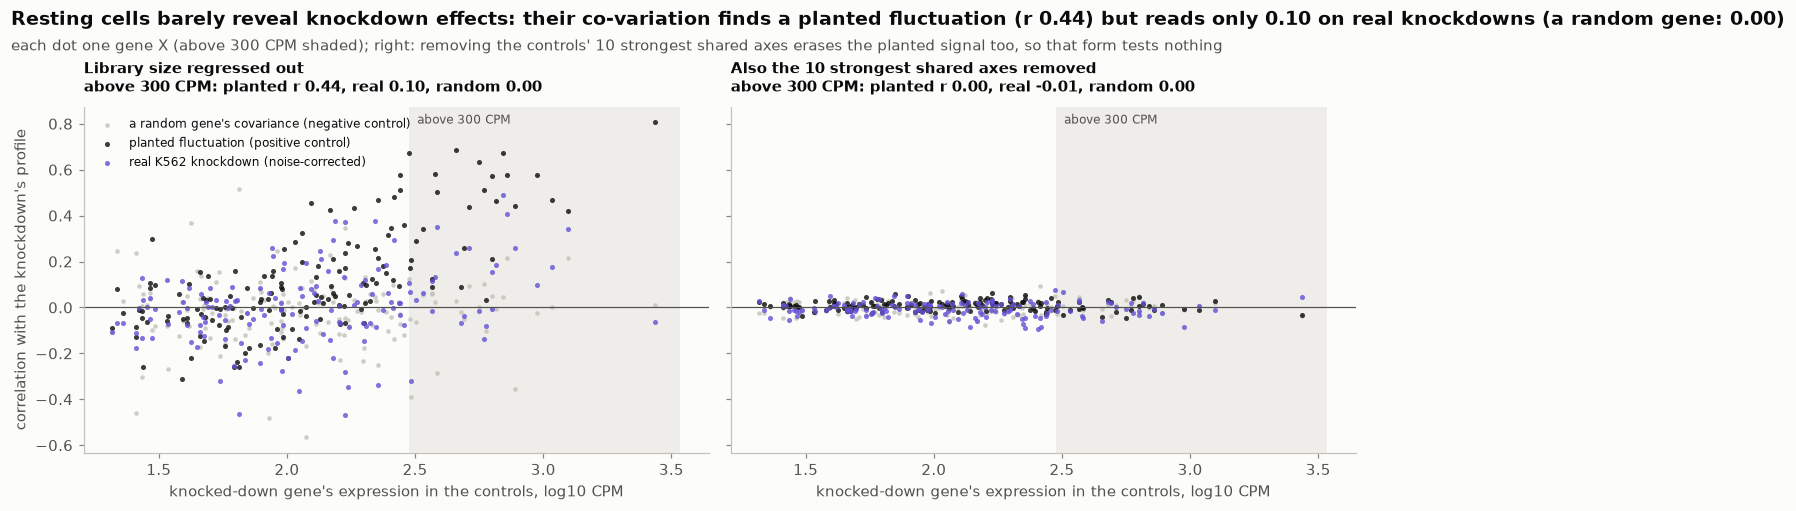

In [48]:
# The figure: the correlations per knocked-down gene, for both forms of the test.
tested_target_cpm = k562_cpm[targets]
# targets expressed well enough for half the controls to see them move
well_expressed = tested_target_cpm > 300
high = {k: np.median(v[well_expressed]) for k, v in library_only.items()}
high_axes = {k: np.median(v[well_expressed]) for k, v in axes_removed.items()}
forms = {
    "Library size regressed out": library_only,
    "Also the 10 strongest shared axes removed": axes_removed,
}
finding = (
    "Resting cells barely reveal knockdown effects: their co-variation finds a planted fluctuation "
    f"(r {high['planted']:.2f}) but reads only {high['real']:.2f} on real knockdowns "
    f"(a random gene: {high['random']:.2f})"
)
fig = plot_dead_end(tested_target_cpm, forms, finding)

In [49]:
# What we learned, in this run's numbers.
print(
    "What we learned: for targets above 300 CPM the covariance finds a planted fluctuation "
    f"(median r {high['planted']:.2f}, {high_axes['planted']:.2f} with shared axes removed) and "
    f"reads {high['real']:.2f} on real knockdowns, {high_axes['real']:.2f} once the shared axes "
    f"are removed; a random gene reads {high['random']:.2f}."
)
planted_r, real_r, random_r = high["planted"], high["real"], high["random"]
EVIDENCE[7] = f"planted r {planted_r:.2f}, real {real_r:.2f}, random {random_r:.2f}"

What we learned: for targets above 300 CPM the covariance finds a planted fluctuation (median r 0.44, 0.00 with shared axes removed) and reads 0.10 on real knockdowns, -0.01 once the shared axes are removed; a random gene reads 0.00.


**The playbook lesson.** A clean negative result with a positive control is knowledge.

## 8. The test harness: leave one line out

**The question.** How do we know a change helps on lines we have never seen? The leaderboard cannot tell us: in
the final round its scores are hidden, and tuning to a public leaderboard's lines overfits them. So we build our
own test that looks like the real one. In software terms it is a staging environment: the same inputs and the
same scorer as production, on data where we know the answer.

**The experiment.** Six training lines whose real knockdown cells are public (H1 stem cells, K562 twice, Jurkat,
RPE1, HepG2). For each one in turn ("a fold"): its control cells and its panel become a one-line phase, exactly
like the challenge's input; **every screen of the same cell type is removed** from the training data first (in
the figure below, the crossed-out squares), so the pipeline meets the line as a stranger; then the official
scorer compares the prediction with the line's real perturbed cells. Each fold is scored for:
- **predicting no change** (the control cells' mean): 0 on the challenge's scale, by its definition;
- **the simple borrowed consensus**: every screen's average response to the knockdown, the recipe the probe of
  section 13 uses;
- **the final pipeline**, and the final pipeline again with another random seed for its cells, whose score
  difference is the noise floor: a change smaller than it is not a change.

*The scores need the official scorer's GPU engine (about 90 scorings, 10 to 15 hours, shared with section 10).
Each score is saved as it lands under `data/scores`, with the time it was made; a rerun reads them instead of
scoring again.*

In [50]:
# The code this section is about (from the package):
show(run_fold)

def run_fold(
    line: str, tables_dir: Path, work: Path, arms: dict, cfg=None, log=print, cache: Path | None = None
) -> dict:
    """One held-out training line: its phase, the references without its own cell types, the probe, then one
    build and one official score per arm. An arm is a list of pieces (seed 0), {"pieces": [...], "seed": n},
    or "probe" (the probe's own cells, the simple borrowed consensus, scored as a baseline). Returns
    {arm: scaled metrics}.
    `cache`: each arm's score is written to cache/<line>/<arm>.json as soon as it exists, with when and how
    long it took; an arm already there is read, not re-scored, so a long chain resumes where it stopped and a
    rerun of the notebook shows the numbers of the run that made them."""
    import gc
    import time

    cfg = dict(cfg or FINAL_CONFIG)
    out, todo = {}, {}
    for arm, spec in arms.items():
        f = None if cache is None else Path(cache) / line / f"{arm}.json"
        if f is not None and f.exists():
            out[arm] = json.loads(f.read_text())["scores"]
        else:
            todo[arm] = spec
    if not todo:
        return {a: out[a] for a in arms}
    bench = Path(tables_dir) / "bench" / line
    panel = pd.read_csv(bench / "panel.csv")["target_gene"].astype(str).tolist()
    phase = fold_phase(bench / "reference.h5ad", panel, line, work / "phase")
    t0 = time.time()
    inp = prepare_phase(phase, tables_dir, work, cfg, log=log, held=HELD_TYPES[line])
    inp["detline"] = probe_phase(phase, inp, work, cfg, log=log, keep="probe" in todo)
    t_prep = time.time() - t0
    for arm, spec in todo.items():
        t1 = time.time()
        if spec == "probe":
            pred, meta = work / "probe.h5ad", {"arm": "probe"}
        else:
            spec = spec if isinstance(spec, dict) else {"pieces": list(spec), "seed": 0}
            pred, meta = work / f"pred_{arm}.h5ad", {"pieces": list(spec["pieces"]), "seed": int(spec.get("seed", 0))}
            build_phase(phase, inp, pred, dict(cfg, pieces=tuple(spec["pieces"])), log=log, seed=meta["seed"])
        out[arm] = score_fold(
            pred, phase, bench / "reference.h5ad", bench / "bundle_work" / "bundle", work / f"score_{arm}"
        )
        pred.unlink()
        gc.collect()
        log(f"fold {line} arm {arm}: " + ", ".join(f"{k} {v:.4f}" for k, v in out[arm].items()))
        if cache is not None:
            f = Path(cache) / line / f"{arm}.json"
            f.parent.mkdir(parents=True, exist_ok=True)
            meta |= {
                "line": line,
                "scored_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
                "seconds": round(time.time() - t1, 1),
                "prepare_and_probe_seconds": round(t_prep, 1),
                "detection_line": {k: inp["detline"][k] for k in ("a", "b")},
                "scores": out[arm],
            }
            f.write_text(json.dumps(meta, indent=1))
    return {a: out[a] for a in arms}

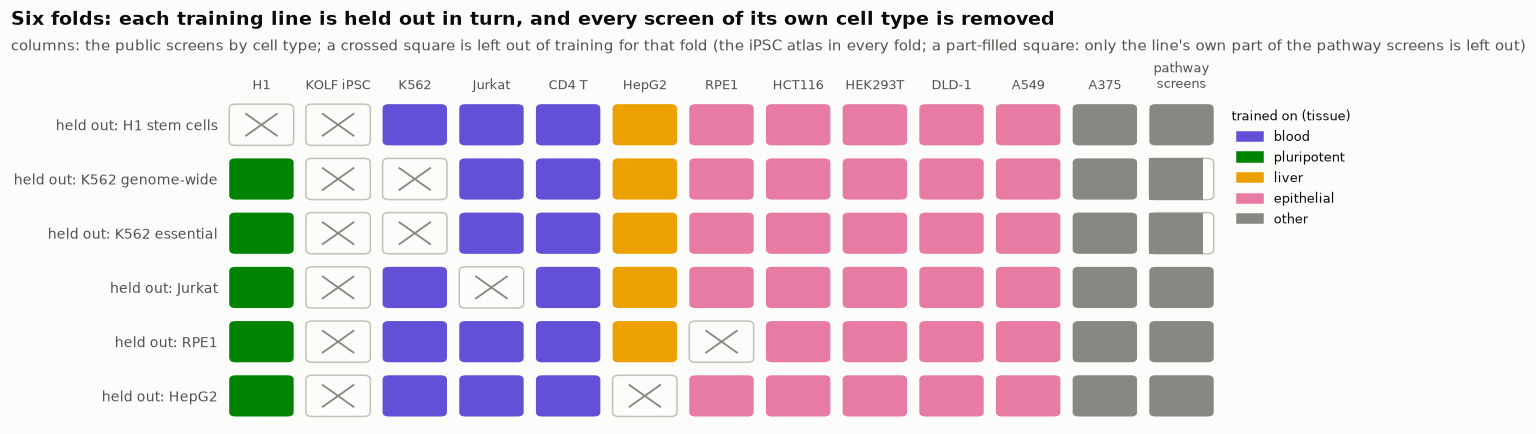

In [51]:
# The figure: the six folds, and what each leaves out of training.
fig = plot_fold_map(FOLD_LINES, HELD_TYPES)

In [52]:
# The official scores are saved per fold and arm; with them (or a GPU) the folds run in FULL mode.
SCORES = Path(os.environ.get("VCC_SCORES", DATA / "scores"))
ARMS = waterfall_arms()
have_scores = all((SCORES / line / f"{a}.json").exists() for line in FOLD_LINES for a in ARMS)
folds_run = MODE == "FULL" and (GPU or have_scores)
NEEDS_SCORES = (
    "skipped: needs the scorer's GPU engine (MODE FULL and a visible GPU), or the saved scores"
)
if folds_run:
    fold_scores = {}
    for line in FOLD_LINES:  # each fold reads its saved scores (or builds and scores, with a GPU)
        fold_scores[line] = run_fold(line, TABLES, WORK / "folds" / line, ARMS, cache=SCORES)
    saved = [SCORES / line / f"{a}.json" for line in FOLD_LINES for a in ARMS]
    made = sorted(json.loads(f.read_text())["scored_utc"] for f in saved)
    print(f"{len(made)} official scorings, made {made[0]} to {made[-1]} (read from {SCORES})")
else:
    print(NEEDS_SCORES)

90 official scorings, made 2026-11-02T14:44:22Z to 2026-11-03T01:30:04Z (read from data/scores)


In [53]:
# Each fold's overall score: borrowed consensus, final pipeline, the final with another seed.
if folds_run:
    final_scores = pd.DataFrame({line: fold_scores[line]["+l2a"] for line in FOLD_LINES}).T
    consensus_scores = pd.DataFrame({line: fold_scores[line]["probe"] for line in FOLD_LINES}).T
    seed_scores = pd.DataFrame({line: fold_scores[line]["final_seed1"] for line in FOLD_LINES}).T
    seed_noise = (final_scores["overall"] - seed_scores["overall"]).abs()  # the noise floor
    overall = {
        "no change": 0.0,
        "borrowed consensus": consensus_scores["overall"],
        "final pipeline": final_scores["overall"],
        "final, other seed": seed_scores["overall"],
    }
    print(pd.DataFrame(overall).round(4).rename(index=FOLD_LABEL).to_string())

                  no change  borrowed consensus  final pipeline  final, other seed
H1 stem cells           0.0              0.2472          0.3276             0.3280
K562 genome-wide        0.0              0.2977          0.4188             0.4207
K562 essential          0.0              0.3688          0.4368             0.4327
Jurkat                  0.0              0.4566          0.4900             0.4898
RPE1                    0.0              0.2444          0.3603             0.3630
HepG2                   0.0              0.2210          0.3101             0.3062


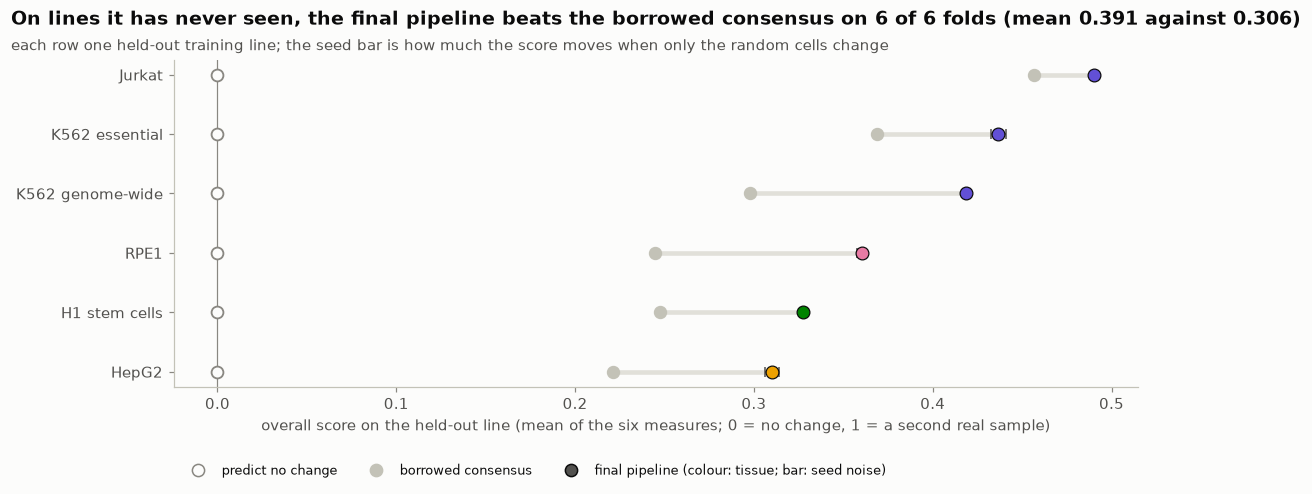

In [54]:
# The figure: the final pipeline against the borrowed consensus, fold by fold.
if folds_run:
    final_mean = final_scores["overall"].mean()
    consensus_mean = consensus_scores["overall"].mean()
    fold_gain = final_scores["overall"] - consensus_scores["overall"]
    finding = (
        "On lines it has never seen, the final pipeline beats the borrowed consensus on "
        f"{int((fold_gain > seed_noise).sum())} of {len(fold_gain)} folds "
        f"(mean {final_mean:.3f} against {consensus_mean:.3f})"
    )
    fig = plot_fold_scores(final_scores, consensus_scores, seed_noise, finding)

In [55]:
# What we learned, in this run's numbers.
if folds_run:
    print(
        f"What we learned: mean overall score {final_mean:.3f} for the final pipeline, "
        f"{consensus_mean:.3f} for the borrowed consensus, 0 for no change; changing only the "
        f"random seed moves a fold's score by {seed_noise.mean():.4f} on average (largest "
        f"{seed_noise.max():.4f})."
    )
    means = f"final {final_mean:.3f}, borrowed consensus {consensus_mean:.3f}"
    EVIDENCE[8] = f"six held-out lines: {means}"

What we learned: mean overall score 0.391 for the final pipeline, 0.306 for the borrowed consensus, 0 for no change; changing only the random seed moves a fold's score by 0.0022 on average (largest 0.0040).


**The playbook lesson.** The harness must look like the test: hold out whole lines, remove their relatives from
training, score with the official scorer; and never tune on the leaderboard.

## 9. Means are not enough

**The question.** This is the section that shaped the whole design. Suppose stage 1 were perfect: we knew each knockdown's true mean expression of every gene.
Would cells drawn around those means score well? Four of the six measures run the rank test on cells, so the
spread of the cells matters as much as their mean.

**The experiment.** On a held-out training line (H1, measured on the challenge's Flex chemistry), 20 typical
knockdowns (the middle of the line's knockdowns ranked by how many genes they move), and their **true** effects. Two generators turn the true effects into
cells: a naive one (every gene a single negative binomial fitted to all controls, scaled by the true fold
change; a negative binomial is the standard model of RNA count noise: Poisson counts whose rate itself varies from
cell to cell) and ours (120 cell states, then each knockdown's pooled counts pinned to the truth exactly). The
scorer's rank test (Wilcoxon rank-sum against the real controls, Benjamini-Hochberg at 0.05 within each
knockdown, computed exactly as cell-eval2 computes it) is run on the real cells and on both generated sets.

In [56]:
# The code this section is about (from the package):
show(pinned_cells)

def pinned_cells(
    model: ControlModel,
    n: int,
    rng: np.random.Generator,
    *,
    fc_cell: np.ndarray,
    p_cell: np.ndarray,
    q_bulk: np.ndarray,
    max_projection: float = 0.03,
) -> sp.csr_matrix:
    """`n` cells for one knockdown: sampled at the per-cell fold change, then fitted so their
    mean share is `p_cell` and their pseudobulk is exactly `q_bulk` (rounded)."""
    cells = sample_cells(model, n, rng, fold_change=np.asarray(fc_cell))
    template = np.asarray(cells.todense(), dtype=np.float64)
    depths = template.sum(axis=1).astype(np.int64)
    if (depths < 1).any():  # an empty draw: give it one count of the commonest gene
        template[depths < 1, int(np.argmax(q_bulk))] = 1.0
        depths = template.sum(axis=1).astype(np.int64)
    p_cell = feasible_cell_target(p_cell, q_bulk, depths / depths.mean())
    counts = dual_moment_counts(
        template, p_cell, q_bulk, depths=depths, seed=int(rng.integers(2**32)), max_projection=max_projection
    )
    return sp.csr_matrix(counts.astype(np.float32))

In [57]:
# H1 (2025 challenge, Flex chemistry): its controls, and each knockdown's true log2 fold change.
h1 = ad.read_h5ad(TABLES / "bench" / "h1" / "reference.h5ad")
h1_labels = h1.obs["target_gene"].astype(str).to_numpy()
h1_counts = sp.csr_matrix(h1.X)
h1_genes = list(h1.var_names.astype(str))
h1_controls = h1_counts[h1_labels == "non-targeting"]
h1_cpm = mean_cpm(h1_controls)
h1_tested = h1_cpm > 5  # the genes the rank test is run on


def h1_true_lfc(p):
    """Knockdown p's true log2 fold change per gene."""
    return np.log2(np.maximum(mean_cpm(h1_counts[h1_labels == p]), 1e-9) / np.maximum(h1_cpm, 1e-9))


# 20 typical knockdowns: the middle of the line's knockdowns, ranked by the genes they move.
strength = {}
for p in sorted(set(h1_labels) - {"non-targeting"}):
    strength[p] = int(((np.abs(h1_true_lfc(p)) > 0.5) & h1_tested).sum())
ranked = sorted(strength, key=lambda p: -strength[p])
example_kds = ranked[len(ranked) // 2 - 10 : len(ranked) // 2 + 10]

In [58]:
# The two generators, fitted to the controls: one cell state (naive) and 120 cell states (ours).
cell_rng = np.random.default_rng(0)
naive_model = fit_controls(h1_controls, n_states=1, seed=0)
our_model = fit_controls(h1_controls, n_states=120, seed=0)


def generate(p):
    """Knockdown p's real cells, and as many cells from each generator given its true effects."""
    real = h1_counts[h1_labels == p]
    n_cells = real.shape[0]
    q_bulk = np.asarray(real.sum(axis=0, dtype=np.float64)).ravel()
    q_bulk = q_bulk / q_bulk.sum()  # the knockdown's pooled profile
    totals = np.maximum(np.asarray(real.sum(1)).ravel(), 1)
    per_cell = sp.diags(1.0 / totals) @ real  # each cell scaled to a total of 1
    p_cell = np.asarray(per_cell.mean(axis=0), np.float64).ravel()
    p_cell /= p_cell.sum()  # the knockdown's average cell
    fc = np.where(h1_cpm > 0, mean_cpm(real) / np.maximum(h1_cpm, 1e-12), 1.0)  # true fold change
    naive = sample_cells(naive_model, n_cells, cell_rng, fold_change=fc)
    ours = pinned_cells(our_model, n_cells, cell_rng, fc_cell=fc, p_cell=p_cell, q_bulk=q_bulk)
    return real, naive, ours


generated = [generate(p) for p in example_kds]  # (real, naive, ours) per knockdown
set_names = ["real", "naive generator", "our generator"]
cell_sets = {name: [g[k] for g in generated] for k, name in enumerate(set_names)}

In [59]:
# The scorer's rank test on every set (computed exactly: it reproduces cell-eval2's p-values).
h1_ranks = ControlRanks(h1_controls, h1_tested)


def called_pairs(blocks):
    """The (knockdown, gene) pairs the rank test calls in a set of cells: Benjamini-Hochberg at
    0.05 within each knockdown, the knocked-down gene itself left out."""
    calls = set()
    for p, cells in zip(example_kds, blocks):
        pv = 2 * norm.sf(np.abs(h1_ranks.z(cells)[h1_tested]))
        hit = np.flatnonzero(h1_tested)[false_discovery_control(pv, method="bh") < 0.05]
        calls |= {(p, h1_genes[g]) for g in hit if h1_genes[g] != p}
    return calls


calls = {name: called_pairs(blocks) for name, blocks in cell_sets.items()}
true_calls = calls["real"]
generators = ["naive generator", "our generator"]
found_calls = [len(calls[n] & true_calls) for n in generators]
false_calls = [len(calls[n] - true_calls) for n in generators]
call_summary = [
    f"{n}: {len(calls[n])} calls, {found} of the real test's {len(true_calls)} found, {false} false"
    for n, found, false in zip(generators, found_calls, false_calls)
]
print("\n".join(call_summary))

naive generator: 16853 calls, 3663 of the real test's 4525 found, 13190 false
our generator: 5677 calls, 3660 of the real test's 4525 found, 2017 false


In [60]:
# The example: a gene the naive cells get called on, but neither the real nor our cells do (the
# best expressed of those).
h1_gene_index = {g: i for i, g in enumerate(h1_genes)}


def real_mean(pair):
    """The real cells' mean count of the pair's gene in the pair's knockdown."""
    kd, gene = pair
    real = cell_sets["real"][example_kds.index(kd)]
    return float(np.asarray(real[:, h1_gene_index[gene]].mean()))


naive_only = sorted(calls["naive generator"] - true_calls - calls["our generator"])
example_pair = max(naive_only, key=real_mean)
shape_kd, shape_gene = example_pair
kd_row, gene_col = example_kds.index(shape_kd), h1_gene_index[shape_gene]
example_counts = {}  # the example gene's counts per cell, in each set
for set_name, cells in cell_sets.items():
    example_counts[set_name] = np.asarray(cells[kd_row][:, gene_col].todense()).ravel()
example_called = {name: example_pair in calls[name] for name in cell_sets}

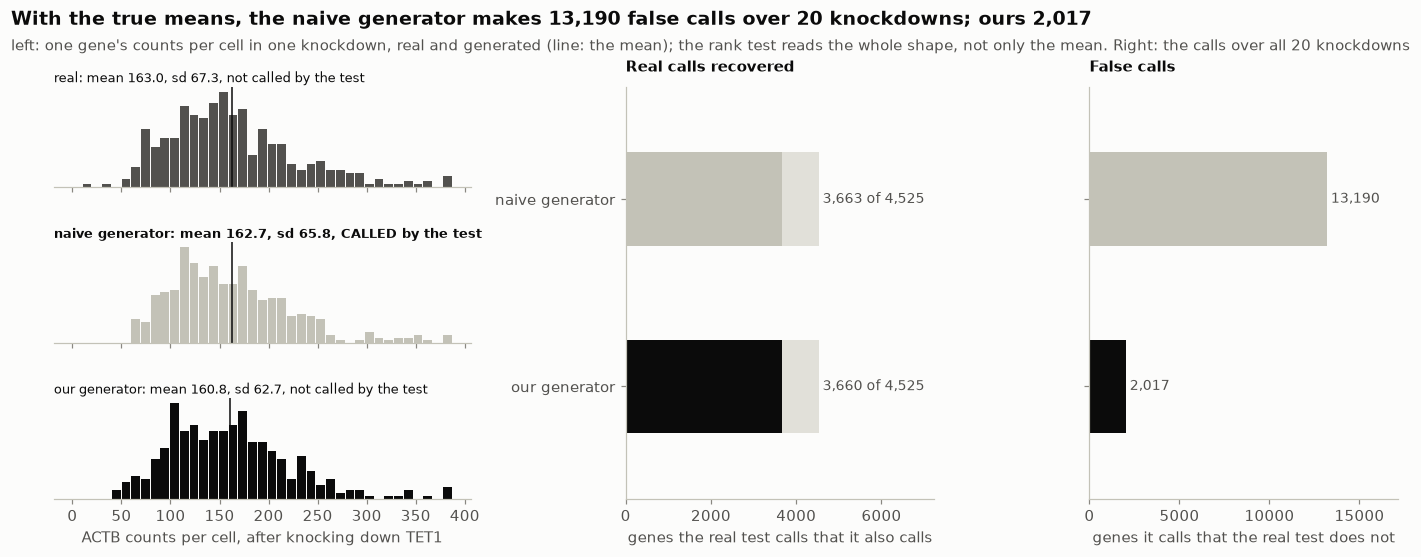

In [61]:
# The figure: the example gene's counts, and every generator's calls.
naive_false, our_false = false_calls
finding = (
    f"With the true means, the naive generator makes {naive_false:,} false calls over 20 "
    f"knockdowns; ours {our_false:,}"
)
example = (example_counts, example_called, shape_gene, shape_kd)
fig = plot_cell_shape(*example, found_calls, false_calls, len(true_calls), finding)

In [62]:
# What we learned, in this run's numbers.
print(
    f"What we learned: with the true effects, naive cells make {naive_false:,} false calls over "
    f"20 knockdowns, ours {our_false:,}, while both recover about the same true calls "
    f"({found_calls[0]:,} vs {found_calls[1]:,} of {len(true_calls):,})."
)
EVIDENCE[9] = (
    f"with true means: {naive_false:,} false calls (naive cells) against {our_false:,} (ours)"
)

What we learned: with the true effects, naive cells make 13,190 false calls over 20 knockdowns, ours 2,017, while both recover about the same true calls (3,663 vs 3,660 of 4,525).


**The playbook lesson.** Match the evaluation's statistic, not only the target's mean.

## 10. Stage 1, the effect model, built piece by piece

**The question.** Stage 1 is a stack of small pieces, each a correction we found by measurement. Which of them
earn their place on lines the pipeline has never seen?

**The experiment.** Start from the bare recipe (every piece off), switch the pieces on one at a time in the
order they were added, and score every step on the six folds of section 8. A piece's gain is the change in the
mean overall score when it is switched on. The **noise band** is the score change caused by nothing but a new
random seed for the generated cells (section 8): a gain inside it is indistinguishable from luck.

**The pieces**, in plain words (a "profile" is one knockdown's predicted change over all genes; stage 1 makes one
pooled profile per knockdown, and the per-cell changes stage 2 samples around):
- `gate`: entries of a borrowed profile that no screen measured as significant (|change| / standard error > 3) are
  shrunk to 0.3 of their size: keep the signal, quieten the rest;
- `weakwh`: knockdowns whose screens agree poorly (below the median weight) are whitened against the others, so
  they stop all looking like the response every knockdown shares;
- `cis3`: the neighbour prior counted three times in the pooled profile (CRISPRi also silences genes whose start
  sites sit next to the target's);
- `agree_clean`: each knockdown's weight from how well the cell types agree once each type's dominant shared
  component is removed;
- `cell_caps`: per-cell changes compressed above the line's detection threshold, and capped where no screen
  called the gene;
- `down_floor`: small decreases lifted to half the detection threshold instead of three quarters;
- `ps20`: the borrowed profiles computed with a pseudocount of 20, so a few counts cannot make a large change;
- `whiten_tol`: a numerical tolerance for that whitening;
- `k_loto`: each knockdown's loudness from how well each cell type is predicted by the others (leave one type out);
- `s2`: the loudest 20% of profiles pulled towards the target line's own axes of variation, read from its controls;
- `e`: the learned combiner's profile blended into the loudest knockdowns that four or more cell types measured;
- `l2a`: a second weak-row whitening, against the other rows' axes.

In [63]:
# The code this section is about (from the package):
show(moments_final)

def moments_final(controls, perts, genes, ctx, inp, cfg):
    """The final recipe's targets for one context: {pert: (bulk lfc, per-cell lfc)}.

    Bulk: the ps20 direction, its weak rows Gram-whitened, entries outside the sources' gate x0.3, an
    amplitude per knockdown from the types' leave-one-type-out agreement (k_loto), the loudest 20% pulled
    toward the line's own control axes (S2), E blended into the loudest well-covered rows, weak-row
    whitening (l2a), the p53 response restored on a line whose p53 works, all scaled so the profiles'
    spread is the measured noise budget; plus 3 x cis.
    Cells: the stack direction x max(2, table), compressed above the detection line, capped at the line
    outside the gate, small changes lifted to a floor (0.75 x the line up, 0.5 x down); plus cis."""
    on = set(cfg.get("pieces", PIECES)).__contains__  # the waterfall switches every piece; all on = the final
    gi = {g: i for i, g in enumerate(genes)}
    own = np.array([gi.get(p, -1) for p in perts])
    L = (inp["ps_dir"] if on("ps20") else inp["stack_dir"]).astype(np.float64)
    Lc = inp["stack_dir"].astype(np.float64)
    cis = inp["cis"].astype(np.float64)
    T = inp["T"]
    ccpm = mean_cpm(controls)
    floor = cfg["floor"]
    # agreement of the type rows after each type loses its panel top component (the bulk's key)
    expr = ccpm > 5
    Tc = {}
    for t, Mt in T.items():
        Xe = np.nan_to_num(Mt[:, expr])
        have = np.isfinite(Mt[:, expr]).mean(1) > 0.5
        Z = np.full(Mt.shape, np.nan)
        if have.sum() >= 10:
            _, _, Vt = np.linalg.svd(Xe[have] - Xe[have].mean(0), full_matrices=False)
            v = Vt[0]
            Z[:, expr] = Mt[:, expr] - np.outer(Xe @ v, v)
        else:
            Z[:, expr] = Mt[:, expr]
        Tc[t] = Z
    agree_c = agreement(Tc, expr)
    agree = agreement(T, ccpm > 5)
    w = weights(agree, floor)
    medB = np.asarray(inp["medB"][ctx], np.float64)
    medB = np.where(np.isfinite(medB), medB, np.nanmedian(medB))
    w = np.maximum(agree, 0) ** 0.5 * medB**0.5
    w = np.maximum(w / np.median(w[w > 0]), floor)
    w_c = np.maximum(agree_c, 0) ** 0.5 * medB**0.5
    w_c = np.maximum(w_c / np.median(w_c[w_c > 0]), floor)
    Lb = L.copy()
    nrm = np.linalg.norm(Lb, axis=1)
    if on("weakwh"):  # weak rows (below the median weight) fully Gram-whitened
        W = gram_whiten(Lb, tol=cfg["whiten_tol"] if on("whiten_tol") else None)
        t_ = np.where(w < np.median(w), 1.0, 0.0)
        Lb = (1 - t_)[:, None] * Lb + t_[:, None] * W
        Lb = Lb * (nrm / np.maximum(np.linalg.norm(Lb, axis=1), 1e-12))[:, None]
    if on("gate"):
        keep = inp["gate"].astype(bool) & (ccpm > 5)[None, :]
        Lb = np.where(keep, Lb, cfg["gate_bg"] * Lb)
        Lb = Lb * (nrm / np.maximum(np.linalg.norm(Lb, axis=1), 1e-12))[:, None]
    csum = np.asarray(controls.sum(axis=0)).ravel()
    wb = w_c if on("agree_clean") else w
    # the amplitude: k_loto (fallback: the current amplitude x the median ratio), floored, cis rescaled with it
    info = {}
    cis_r = np.ones(len(perts))
    if on("k_loto"):
        kl = k_loto_of(T, ccpm > 5)
        nb = np.linalg.norm(Lb, axis=1)
        cur = wb * nb
        okl = np.isfinite(kl) & (nb > 0)
        ratio = float(np.median(kl[okl] / np.maximum(cur[okl], 1e-12)))
        amp_new = np.where(okl, kl / ratio, cur)
        amp_new = np.maximum(amp_new, 0.25 * np.median(cur[nb > 0]))
        cis_r = np.where(cur > 0, amp_new / np.maximum(cur, 1e-12), 1.0)
        wb = np.where(nb > 0, amp_new / np.maximum(nb, 1e-12), wb)
        info.update(loto_n=int(okl.sum()), loto_ratio=ratio)
    if on("s2"):  # S2: the loudest rows pulled toward the line's own control axes (PCs K0..K), norms kept
        k_s, lam_s, f_s, k0_s = cfg["smooth"]
        nb_s = np.linalg.norm(Lb, axis=1)
        rows_s = np.argsort(-(wb * nb_s))[: round(f_s * len(perts))]
        p0 = csum / csum.sum()
        dslope = (TS * p0) / (1.0 + TS * p0)
     

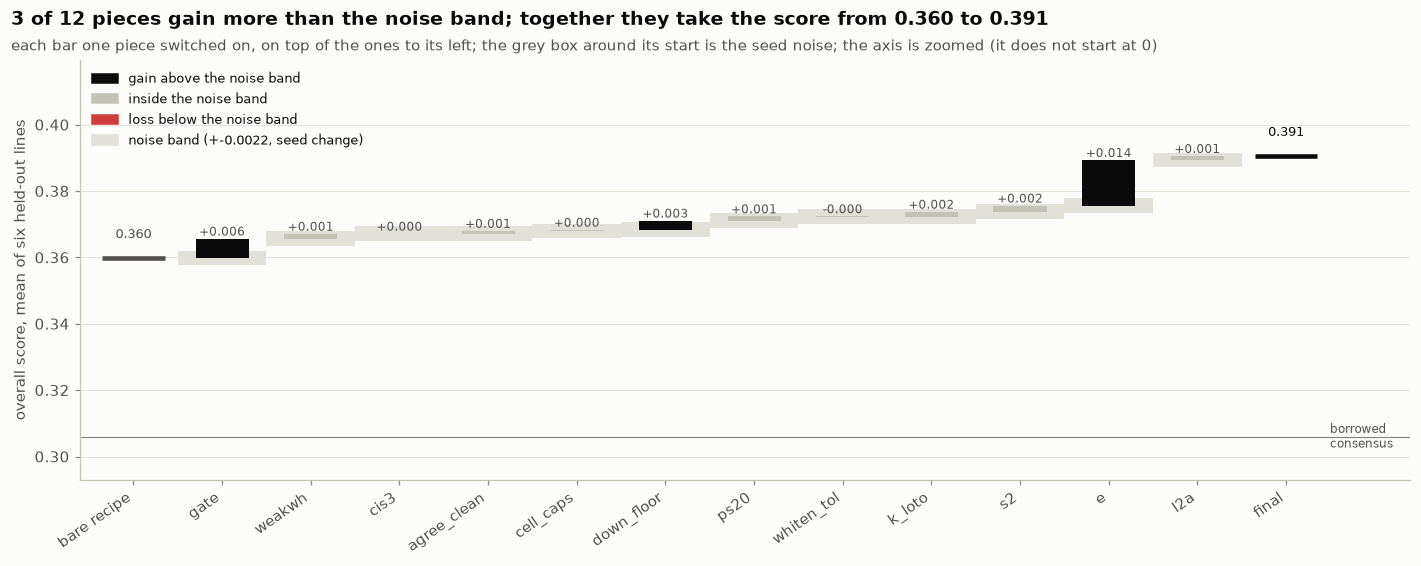

In [64]:
# The mean overall score of the six folds after each step, each piece's gain, and the noise band.
if folds_run:
    steps = ["none"] + [f"+{piece}" for piece in WATERFALL]
    step_scores = {line: {a: fold_scores[line][a]["overall"] for a in steps} for line in FOLD_LINES}
    overall_by_step = pd.DataFrame(step_scores)  # steps x lines
    mean_by_step = overall_by_step.mean(axis=1)
    gains = mean_by_step.diff().iloc[1:]
    band = float(seed_noise.mean())  # the score change from a new seed alone (section 8)
    n_above = int((gains > band).sum())
    bare_score, final_score = mean_by_step.iloc[0], mean_by_step.iloc[-1]
    finding = (
        f"{n_above} of {len(gains)} pieces gain more than the noise band; together they take the "
        f"score from {bare_score:.3f} to {final_score:.3f}"
    )
    fig = plot_waterfall(mean_by_step, gains, band, float(consensus_mean), finding)

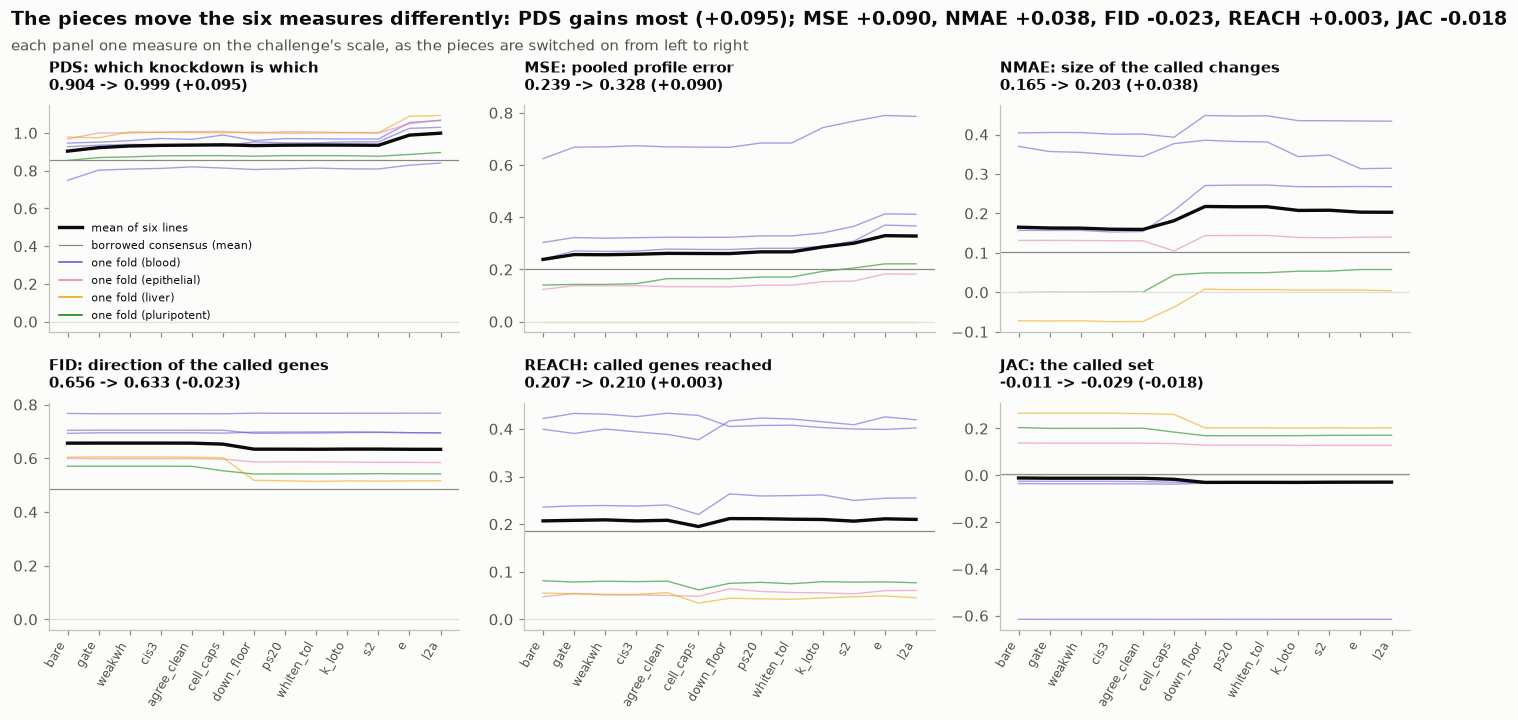

In [65]:
# What each measure gains from the bare recipe to the final pipeline, mean over the folds.
def measure_gain(m):
    """Measure m's mean change over the folds, from the bare recipe to the final pipeline."""
    changes = [fold_scores[line]["+l2a"][m] - fold_scores[line]["none"][m] for line in FOLD_LINES]
    return float(np.mean(changes))


if folds_run:
    moved = {m: measure_gain(m) for m in SCORER_METRICS}
    best_measure = max(moved, key=moved.get)
    others = ", ".join(f"{m.upper()} {v:+.3f}" for m, v in moved.items() if m != best_measure)
    finding = (
        f"The pieces move the six measures differently: {best_measure.upper()} gains most "
        f"({moved[best_measure]:+.3f}); {others}"
    )
    fig = plot_measures(fold_scores, steps, finding)

In [66]:
# Each piece's gain, whether it sits inside the noise band, and the folds it helps.
if folds_run:
    before, after = steps[:-1], steps[1:]
    step_gain = [overall_by_step.loc[a] - overall_by_step.loc[b] for b, a in zip(before, after)]
    lines_helped = [(g > 0).sum() for g in step_gain]  # the folds a piece raises
    inside = gains.abs() <= band
    piece_table = pd.DataFrame(
        {"gain": gains.round(4), "inside the noise band": inside, "lines it helps": lines_helped}
    )
    piece_table.index = [a[1:] for a in piece_table.index]
    print(piece_table.to_string())
    n_inside, n_lose = int(inside.sum()), int((gains < -band).sum())
    print(
        f"What we learned: from the bare recipe {bare_score:.3f} to the final {final_score:.3f} "
        f"({final_score - bare_score:+.3f}) on six held-out lines; {n_above} pieces gain more "
        f"than the noise band ({band:.4f}), {n_inside} sit inside it, {n_lose} lose."
    )
    EVIDENCE[10] = f"{n_above} of {len(gains)} pieces above the noise band ({band:.4f})"
else:
    print(NEEDS_SCORES)

               gain  inside the noise band  lines it helps
gate         0.0059                  False               5
weakwh       0.0014                   True               5
cis3         0.0000                   True               3
agree_clean  0.0008                   True               4
cell_caps    0.0003                   True               3
down_floor   0.0027                  False               4
ps20         0.0013                   True               5
whiten_tol  -0.0001                   True               3
k_loto       0.0015                   True               6
s2           0.0018                   True               5
e            0.0137                  False               6
l2a          0.0012                   True               5
What we learned: from the bare recipe 0.360 to the final 0.391 (+0.031) on six held-out lines; 3 pieces gain more than the noise band (0.0022), 9 sit inside it, 0 lose.


**The playbook lesson.** Add a piece only if it beats the noise floor on held-out data; measure it again when the
pieces around it change, and delete the ones that stop paying.

## 11. Stage 2, the cell generator, against real cells

**The question.** Section 9 showed that the cells' shape decides what the rank test calls. How close are the
generated cells to real ones, gene by gene?

**The experiment.** The same 20 H1 knockdowns and true effects as section 9. For every gene: its mean and
variance across a knockdown's cells (real vs generated), the share of cells in which it is detected at all, and each
knockdown's counts per cell.

In [67]:
# The code this section is about (from the package):
show(fit_controls)

def fit_controls(X: sp.csr_matrix, n_states: int = 1, seed: int = 0) -> ControlModel:
    """The control model of one line, from its control cells `X` (cells x genes, counts).

    `n_states` cell states are found by k-means (`seed`); 1 means a single state. Returns a ControlModel.
    """
    X = sp.csr_matrix(X)
    labels = np.zeros(X.shape[0], dtype=int) if n_states == 1 else cell_states(X, n_states, seed)
    present = np.unique(labels)
    weights = np.array([(labels == k).mean() for k in present])
    states = [_fit_state(X[labels == k]) for k in present]
    return ControlModel(
        weights, states, np.stack([s.proportions for s in states]), np.stack([s.inv_theta for s in states])
    )

In [68]:
# Per gene and knockdown, in each set of cells: the mean, the variance, the share detecting it.
def gene_moments(blocks):
    """(mean, variance, detected share) of every gene in every block of cells, block after block."""
    means, variances, detected = [], [], []
    for block in blocks:
        dense = block.todense() if sp.issparse(block) else block
        dense = np.asarray(dense, np.float64)
        means.append(dense.mean(0))
        variances.append(dense.var(0))
        detected.append((dense > 0).mean(0))
    return np.concatenate(means), np.concatenate(variances), np.concatenate(detected)


moments = {name: gene_moments(blocks) for name, blocks in cell_sets.items()}
compared_kd_genes = np.tile(h1_tested, len(example_kds)) & (moments["real"][0] > 0.05)

In [69]:
# Per knockdown: the median counts per cell of the generated cells against the real ones (log2).
def library_gap(generator):
    """log2 (generated / real median counts per cell), one value per knockdown."""
    gaps = []
    for gen, real in zip(cell_sets[generator], cell_sets["real"]):
        gen_depth, real_depth = np.asarray(gen.sum(1)).ravel(), np.asarray(real.sum(1)).ravel()
        ratio = np.median(gen_depth) / np.median(real_depth)
        gaps.append(np.log2(ratio))
    return np.array(gaps)


depth_gap = {name: library_gap(name) for name in generators}
print({n: f"median |log2 gap| {np.median(np.abs(g)):.3f}" for n, g in depth_gap.items()})

{'naive generator': 'median |log2 gap| 0.040', 'our generator': 'median |log2 gap| 0.031'}


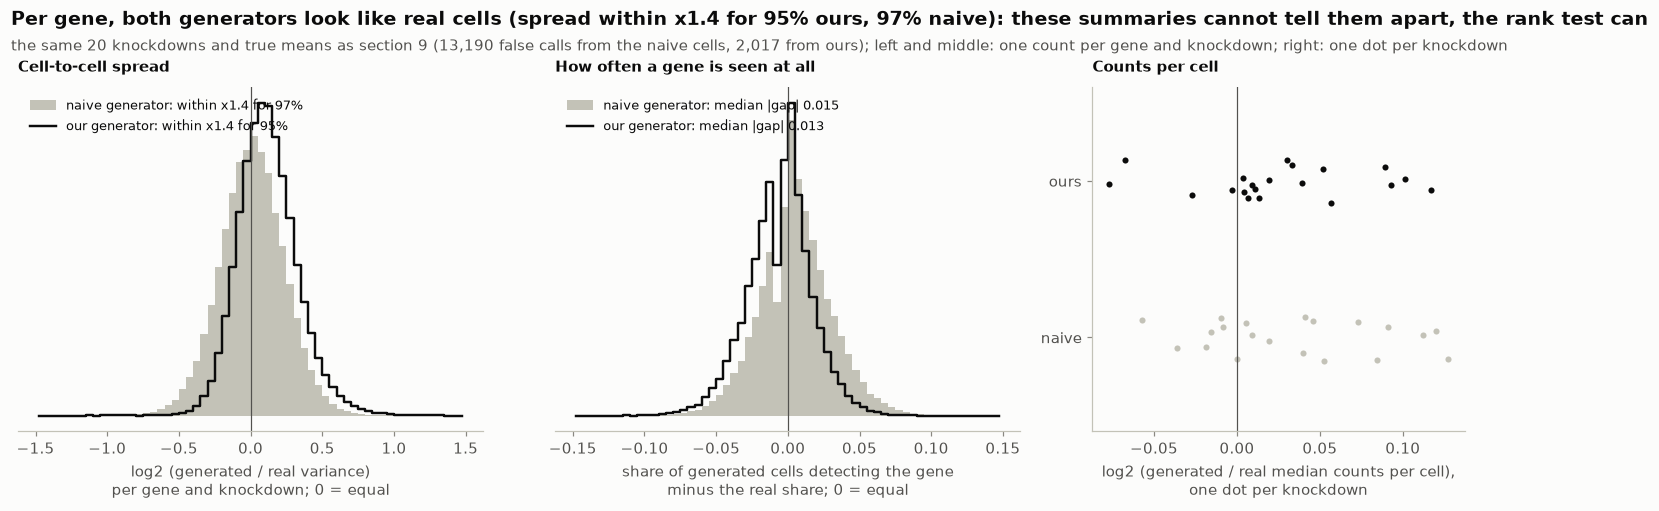

In [70]:
# The figure: generated against real cells, gene by gene.
real_var = moments["real"][1][compared_kd_genes]
gen_var = {n: moments[n][1][compared_kd_genes] for n in generators}
spread_ratio = {n: np.log2((gen_var[n] + 1e-3) / (real_var + 1e-3)) for n in generators}
close_spread = {n: np.mean(np.abs(v) < 0.5) for n, v in spread_ratio.items()}  # within x1.4
finding = (
    "Per gene, both generators look like real cells (spread within x1.4 for "
    f"{close_spread['our generator']:.0%} ours, {close_spread['naive generator']:.0%} naive): "
    "these summaries cannot tell them apart, the rank test can"
)
fig = plot_generator_check(moments, compared_kd_genes, depth_gap, false_calls, finding)

In [71]:
# What we learned, in this run's numbers.
shares = ", ".join(f"{v:.0%} ({n})" for n, v in close_spread.items())
fold_apart = naive_false / max(our_false, 1)  # section 9's false calls, naive over ours
print(
    "What we learned: per gene, generated cell-to-cell variance sits within a factor 1.4 of the "
    f"real one for {shares} of gene x knockdown pairs, and detection and depth are as close; yet "
    f"section 9's rank test separates the two generators {fold_apart:.1f}-fold in false calls. The "
    "test reads the whole distribution of each gene (section 9's example gene: nearly the same "
    "mean and spread, a different shape), so the generator is judged by running the test itself."
)
EVIDENCE[11] = (
    f"spread within x1.4 for {close_spread['our generator']:.0%} of gene x knockdown pairs"
)

What we learned: per gene, generated cell-to-cell variance sits within a factor 1.4 of the real one for 97% (naive generator), 95% (our generator) of gene x knockdown pairs, and detection and depth are as close; yet section 9's rank test separates the two generators 6.5-fold in false calls. The test reads the whole distribution of each gene (section 9's example gene: nearly the same mean and spread, a different shape), so the generator is judged by running the test itself.


**The playbook lesson.** The last step decides what the metric sees: check the generator against real cells on its own.

## 12. What did not work, and why

These ideas were tried and closed before the final. The numbers below are **quoted from our records**, not
recomputed here: each was measured with the official scorer on held-out training lines or on the validation
leaderboard, in the pipeline of its time. They are kept so nobody repeats them.

| idea | what we measured (quoted) | why it closed |
|---|---|---|
| **A trained stage 1** (a bilinear ridge over gene and line features, 300 components) | overall 0.131 on six held-out lines vs 0.252 for borrowing the public screens' mean effect; on the validation leaderboard -0.021 vs +0.092 | learned weights did not beat plain borrowing |
| **A small neural network on top of it** | -0.004 overall on six held-out lines | no gain over the linear model |
| **A learned bulk direction** (gradient-boosted trees on the pooled change) | -0.031 / +0.003 / -0.087 / -0.011 on four held-out lines | it learned one shared direction for every knockdown |
| **A large pretrained perturbation model, zero-shot** (Arc's State) | Pearson of predicted vs true change 0.10-0.26 vs 0.30-0.37 for borrowing, on every line of its own split | below the simple baseline; fine-tuning was never run |
| **Pretrained gene embeddings** (Geneformer, scGPT, Tahoe-x1) as features | 0.058-0.060 vs 0.052 for the plain average, on six held-out lines | within the noise floor |
| **A rank-based post-processing step** (moving single counts between cells so each gene's rank test follows the model's confidence) | REACH +0.008 to +0.012 on H1, small NMAE losses; on the leaderboard it rode in a bundle whose REACH fell by 0.013 | it shapes cells to the test rather than to biology; we kept it out of the final by a team decision |
| **A shallow screen of the same cell type from another lab** (K562 on 10x Flex, weight 0.5 / 1 / 2) | -0.0018 / -0.0001 / -0.0111 overall on the K562 genome-wide line | too few cells per knockdown to add signal; a deep screen of the line itself is another matter |

**The lesson.** With ~6 perturbed cell lines to learn from, the bottleneck is data across cell types, not model
capacity: simple, well-measured statistics beat learned models here, and every negative above was measured
against a baseline before it was dropped.

## 13. The final build: what we predict for D, E and F (FULL mode)

**The question.** Everything so far was measured on lines we could score. Now the pipeline meets the three lines
we cannot: what does it predict, and is the file sound?

**The experiment.** From the final lines' controls and the public tables: the references for this phase, the probe
(simple cells run through the official scorer's test, to measure where each line's test starts calling genes: its
detection line), then stage 1 and stage 2 for every line. The build asserts the submission's rules as it writes
(400 cells per knockdown in every line, whole counts, the challenge's gene order, no cell labelled as a control,
each line's cells closest to its own controls). Then the file is compared with our reference build of the same
pipeline, checked again from disk, and looked at.

The p53 restore fires on D and E, and on this panel it changes no knockdown: the panel avoids essential genes,
and the only p53-wild-type screens (RPE1 and HepG2) measured essential genes only.

In [72]:
# The code this section is about: stage 1 for one line, and the probe's detection line.
show(predict_context)
show(detection_line)

def predict_context(controls, perturbations, ctx, inp, cfg=FINAL_CONFIG):
    """Stage 1 for one context: {knockdown: (bulk log2FC, per-cell log2FC)}. `inp` holds the references
    built for the phase (prepare_phase + the probe's detection line)."""
    assert list(perturbations) == inp["perts"]
    return moments_final(sp.csr_matrix(controls), list(perturbations), inp["genes"], ctx, inp, cfg)

def detection_line(de_by_ctx: dict, cpm_by_ctx: dict, genes: list) -> dict:
    """Where this line's test starts calling genes: per control-CPM bin, the |log2FC| at which half the
    tested genes are called (p_adj < 0.05), then a power law thr = a CPM^b through the bins."""
    import polars as pl

    gi = {g: i for i, g in enumerate(genes)}
    edges = np.exp(np.linspace(np.log(5), np.log(5e4), 25))
    X, Y, bins = [], [], []
    for ctx, de in de_by_ctx.items():
        cpm = cpm_by_ctx[ctx]
        de = de.select(["target", "feature", "p_adj", "log2_fold_change"]).filter(pl.col("target") != pl.col("feature"))
        f = de["feature"].to_numpy()
        c = cpm[np.array([gi[x] for x in f])]
        lf = np.abs(de["log2_fold_change"].to_numpy())
        sig = de["p_adj"].to_numpy() < 0.05
        for lo, hi in pairwise(edges):
            m = (c >= lo) & (c < hi) & np.isfinite(lf)
            if m.sum() < 2000:
                continue
            q = np.quantile(lf[m], np.linspace(0, 0.999, 200))
            share = np.array(
                [
                    sig[m & (lf >= a) & (lf < b)].mean() if (m & (lf >= a) & (lf < b)).sum() > 30 else np.nan
                    for a, b in pairwise(q)
                ]
            )
            mid = (q[:-1] + q[1:]) / 2
            k = np.flatnonzero(np.isfinite(share) & (share >= 0.5))
            if k.size:
                X.append(np.sqrt(lo * hi))
                Y.append(float(mid[k[0]]))
                bins.append({"ctx": ctx, "cpm": X[-1], "thr": Y[-1], "n": int(m.sum())})
    b, loga = np.polyfit(np.log(X), np.log(Y), 1)
    return {"bins": bins, "a": float(np.exp(loga)), "b": float(b)}

In [73]:
# Our reference build of the final file: the same pipeline, run the day the final controls
# arrived. The notebook's file is uploaded only if it is identical to it, or if every
# difference is measured and explained.
REFERENCE_H5AD_SHA256 = "03540c92d8d73268d6681db181b2f8219676845ddada075de67aec1f94d0b307"
REFERENCE_VCC_SHA256 = "09336ea07b253ed4da9d1369a42af36285fe7700b763418d425f769e118d5497"
# Key 1 of the p53 rule: our curated p53 status of the lines D and E match best (both
# wild-type); key 2 is read from each line's own controls inside prepare_phase.
P53_WILD_TYPE = ("D", "E")
# The probe's detection line on D/E/F (thr = a CPM^b, the |log2FC| at which the scorer calls
# half the genes), as our reference build measured it with the scorer's GPU engine. With a GPU
# the notebook measures its own and compares; without one it uses these values, so the file
# is the same either way.
DETLINE_DEF = {"a": 1.9209098540810403, "b": -0.4522164154364011}

In [74]:
# Stage 1's inputs: the references from the public tables, and each line's p53 status.
if MODE == "FULL":
    WORK.mkdir(parents=True, exist_ok=True)
    inp = prepare_phase(PHASE, TABLES, WORK, p53_wild_type=P53_WILD_TYPE)
    for c, status in inp["tp53_status"].items():
        second, restore = status["key2"], "on" if status["fire"] else "off"
        second_text = f"key 2 {second['call']} (score {second['score']:.4f})"
        print(f"p53 line {c}: key 1 {status['key1']}, {second_text}, restore {restore}")
    p53_covered = len(next(iter(inp["tp53"].values()))["keys"]) if inp["tp53"] else 0
    print(f"knockdowns the p53 restore can change: {p53_covered} of {len(inp['perts'])}")

directions, gate, cis ready


levels D: median 225


levels E: median 246


levels F: median 243


E: 1266 keys (433 trained on), training rows per target {'k562': 385, 'cd4t': 404, 'hct116': 382, 'hek293t': 398, 'h1': 208, 'dld1': 103, 'a549': 53, 'rpe1': 38, 'hepg2': 17, 'jurkat': 36}


p53 D: {'key1': 'wild-type', 'key2': {'score': 0.6492250545887759, 'n_genes': 15, 'call': 'agree wild-type'}, 'fire': True}


p53 E: {'key1': 'wild-type', 'key2': {'score': 0.9787110235893745, 'n_genes': 15, 'call': 'agree wild-type'}, 'fire': True}


p53 F: {'key1': 'not called', 'key2': {'score': 0.46339144335521915, 'n_genes': 15, 'call': 'agree wild-type'}, 'fire': False}


p53 line D: key 1 wild-type, key 2 agree wild-type (score 0.6492), restore on
p53 line E: key 1 wild-type, key 2 agree wild-type (score 0.9787), restore on
p53 line F: key 1 not called, key 2 agree wild-type (score 0.4634), restore off
knockdowns the p53 restore can change: 0 of 300


In [75]:
# The probe: where each line's rank test starts calling genes (its detection line).
if MODE == "FULL":
    if GPU:
        inp["detline"] = probe_phase(PHASE, inp, WORK)
        probe_a, probe_b = inp["detline"]["a"], inp["detline"]["b"]
        same_detline = probe_a == DETLINE_DEF["a"] and probe_b == DETLINE_DEF["b"]
        probe = f"this run's probe: a {probe_a!r}, b {probe_b!r}"
        print(f"{probe}; identical to the reference build's: {same_detline}")
    else:  # the probe's calls need the scorer's GPU engine: use the values it measured on D/E/F
        inp["detline"] = dict(DETLINE_DEF)
        print("no GPU: using the detection line measured by the probe on the GPU,", DETLINE_DEF)

[D] 120000 cells, nnz 670051913


[E] 120000 cells, nnz 650020168


[F] 120000 cells, nnz 645941016


detection line: a 1.9209, b -0.4522
this run's probe: a 1.9209098540810403, b -0.4522164154364011; identical to the reference build's: True


In [76]:
# Stage 1 and stage 2 for every line: the submission file.
if MODE == "FULL":
    build_report = build_phase(PHASE, inp, WORK / "prediction.h5ad")
    h5ad_sha = sha256_file(WORK / "prediction.h5ad")
    print("prediction.h5ad sha256", h5ad_sha)
    print("identical to our reference build:", h5ad_sha == REFERENCE_H5AD_SHA256)

[D] 120000 cells, nnz 655228662


[E] 120000 cells, nnz 631411139


[F] 120000 cells, nnz 629279314


prediction.h5ad sha256 03540c92d8d73268d6681db181b2f8219676845ddada075de67aec1f94d0b307
identical to our reference build: True


**The checks.** Before anything is packaged, the file is read back from disk, block by block, and every rule of
the submission is checked again, independently of the code that wrote it.

In [77]:
# Read the file back from disk, block by block: each (line, knockdown)'s summed counts, and,
# on the same pass, what the submission rules check.
if MODE == "FULL":
    file_stats = {}
    file_keys, file_sums, file_genes = group_sums(WORK / "prediction.h5ad", stats=file_stats)
    group_row = {key: i for i, key in enumerate(file_keys)}  # (line, knockdown) -> row of file_sums
    file_lines = sorted({c for c, _ in file_keys})
    file_kds = {c: {p for line, p in file_keys if line == c} for c in contexts}
    file_labels = {p for _, p in file_keys}
    cells_per_group = list(file_stats["cells_per_group"].values())

In [78]:
# Each line's controls on the file's gene axis: cell count, summed counts per gene, mean CPM.
def control_summary(c):
    """(cells, summed counts per gene, mean CPM) of line c's controls."""
    X = read_controls(PHASE, c, file_genes, manifest).X  # cells x genes counts
    return X.shape[0], np.asarray(X.sum(axis=0, dtype=np.float64)).ravel(), mean_cpm(X)


if MODE == "FULL":
    ctrl_cells, ctrl_sum, ctrl_cpm = {}, {}, {}
    for c in contexts:
        ctrl_cells[c], ctrl_sum[c], ctrl_cpm[c] = control_summary(c)

In [79]:
# The label check: each line's average generated cell against every line's average control cell.
def pearson(x, y):
    """The Pearson correlation of two vectors."""
    return float(np.corrcoef(x, y)[0, 1])


def mean_generated_cell(c):
    """log1p of line c's average generated cell: all its knockdowns' counts over all their cells."""
    groups = [(c, p) for p in final_panel if (c, p) in group_row]
    total = sum(file_sums[group_row[g]] for g in groups)
    return np.log1p(total / sum(file_stats["cells_per_group"][g] for g in groups))


if MODE == "FULL":
    generated_cell = {c: mean_generated_cell(c) for c in contexts}
    control_cell = {o: np.log1p(ctrl_sum[o] / ctrl_cells[o]) for o in contexts}
    label_r = {}
    for c in contexts:
        label_r[c] = {o: pearson(generated_cell[c], control_cell[o]) for o in contexts}
    own_vs_next = []
    for c in contexts:
        runner_up = max(v for o, v in label_r[c].items() if o != c)
        own_vs_next.append(f"{c} {label_r[c][c]:.4f} (next {runner_up:.4f})")

In [80]:
# The rules, each checked on what was read back: (rule, what was measured, whether it holds).
if MODE == "FULL":
    control = manifest["control_label"]
    smallest, whole = file_stats["min_count"], file_stats["whole"]
    entries, largest = file_stats["stored_entries"], file_stats["max_cell_total"]
    lo, hi = min(cells_per_group), max(cells_per_group)
    every_kd = all(file_kds[c] == set(final_panel) for c in contexts)
    counts_text = f"smallest stored count {smallest:g}, all whole: {whole}"
    own_closest = all(max(label_r[c], key=label_r[c].get) == c for c in contexts)
    same_as_reference = h5ad_sha == REFERENCE_H5AD_SHA256
    fits_32_bits = entries <= INT32_MAX
    rows = [
        ("contexts", ", ".join(file_lines), file_lines == sorted(contexts)),
        ("every knockdown in every context", f"{len(final_panel)} x {len(contexts)}", every_kd),
        ("no control cells", f"label '{control}' absent", control not in file_labels),
        ("cells per knockdown", f"{lo} to {hi}", lo == hi == CELLS_PER_PERT),
        ("whole, non-negative counts", counts_text, whole and smallest >= 0),
        ("the challenge's gene order", f"{len(file_genes):,} genes", file_genes == final_genes),
        ("each line closest to its own controls", "; ".join(own_vs_next), own_closest),
        ("stored entries fit 32-bit indices", f"{entries:,} of {INT32_MAX:,}", fits_32_bits),
        ("largest total of one cell", f"{largest:,.0f}", largest <= MAX_COUNTS_PER_CELL),
        ("identical to our reference build", f"sha256 {h5ad_sha[:8]}...", same_as_reference),
    ]

In [81]:
# Every rule must pass; the last row (identity with our reference build) is reported, not required.
if MODE == "FULL":
    submission_checks = pass_fail_table(rows)
    display(style_checks(submission_checks))
    assert (submission_checks["pass"] == "PASS").iloc[:-1].all(), "a submission rule failed"
    n_pass = (submission_checks["pass"] == "PASS").sum()
    EVIDENCE[13] = f"{n_pass} of {len(submission_checks)} checks pass"

check,measured,pass
contexts,"D, E, F",PASS
every knockdown in every context,300 x 3,PASS
no control cells,label 'non-targeting' absent,PASS
cells per knockdown,400 to 400,PASS
"whole, non-negative counts","smallest stored count 1, all whole: True",PASS
the challenge's gene order,"18,533 genes",PASS
each line closest to its own controls,D 1.0000 (next 0.6669); E 1.0000 (next 0.8865); F 1.0000 (next 0.8867),PASS
stored entries fit 32-bit indices,"1,915,919,115 of 2,147,483,647",PASS
largest total of one cell,"57,875",PASS
identical to our reference build,sha256 03540c92...,PASS


**What we predict.** For each line and knockdown, the predicted change of every gene: the log2 ratio of the
knockdown's pooled counts to the line's controls scaled to the same total, over genes the line expresses
(CPM > 20), so a handful of counts cannot look like an effect. The knocked-down gene itself is left out (it
always goes down). One knockdown's **effect size** is the length of that vector.

What to expect: every line borrows from the same public screens (none of them of these three lines), and what is
line-specific is read from the line's own controls (which genes it expresses, how sensitive the test is there,
its own axes of variation). So the loudest knockdowns should look alike in every line, and lines that look alike
at rest should be predicted alike.

In [82]:
# Each line's predicted change per knockdown and gene, and each knockdown's effect size.
def predicted_change(c):
    """Line c's predicted log2 change, knockdowns (panel order) x genes: pooled counts against
    the controls scaled to the same total; 0 where the line's CPM is 20 or less, and for the
    knocked-down gene itself."""
    kd_counts = np.vstack([file_sums[group_row[(c, p)]] for p in final_panel])
    expected = ctrl_sum[c][None, :] / ctrl_sum[c].sum() * kd_counts.sum(1, keepdims=True)
    change = np.log2((kd_counts + 1) / (expected + 1))
    change[:, ctrl_cpm[c] <= 20] = 0.0
    for row, p in enumerate(final_panel):
        if p in file_gene_index:
            change[row, file_gene_index[p]] = 0.0
    return change


if MODE == "FULL":
    file_gene_index = {g: i for i, g in enumerate(file_genes)}
    predicted = {c: predicted_change(c) for c in contexts}
    effect_size = {c: np.sqrt((predicted[c] ** 2).sum(1)) for c in contexts}
    largest_kd = {c: final_panel[int(np.argmax(effect_size[c]))] for c in contexts}
    median_size = {c: np.median(effect_size[c]) for c in contexts}
    size_text = {}
    for c in contexts:
        size_text[c] = f"median effect size {median_size[c]:.2f}, largest {largest_kd[c]}"
    print(size_text)

{'D': 'median effect size 4.40, largest SIN3B', 'E': 'median effect size 4.41, largest SIN3B', 'F': 'median effect size 4.45, largest SIN3B'}


In [83]:
# The 25 knockdowns and 30 genes with the strongest predicted change over the three lines,
# clustered so similar rows and columns sit together.
if MODE == "FULL":
    top_kds = np.argsort(-np.mean([effect_size[c] for c in contexts], 0))[:25]
    gene_moved = np.mean([np.abs(predicted[c][top_kds]).sum(0) for c in contexts], 0)
    top_genes = np.argsort(-gene_moved)[:30]
    blocks = {c: predicted[c][np.ix_(top_kds, top_genes)] for c in contexts}
    side_by_side = np.hstack(list(blocks.values()))  # each knockdown's row, line after line
    stacked = np.vstack(list(blocks.values()))  # each gene's column, line under line
    row_order = leaves_list(linkage(side_by_side, "average", metric="correlation"))
    col_order = leaves_list(linkage(stacked.T, "average", metric="correlation"))
    limit = float(np.percentile(np.abs(side_by_side), 98))
    shown = {c: blocks[c][np.ix_(row_order, col_order)] for c in contexts}
    line_pairs = [(a, b) for i, a in enumerate(contexts) for b in contexts[i + 1 :]]
    pattern_r = {(a, b): pearson(shown[a].ravel(), shown[b].ravel()) for a, b in line_pairs}

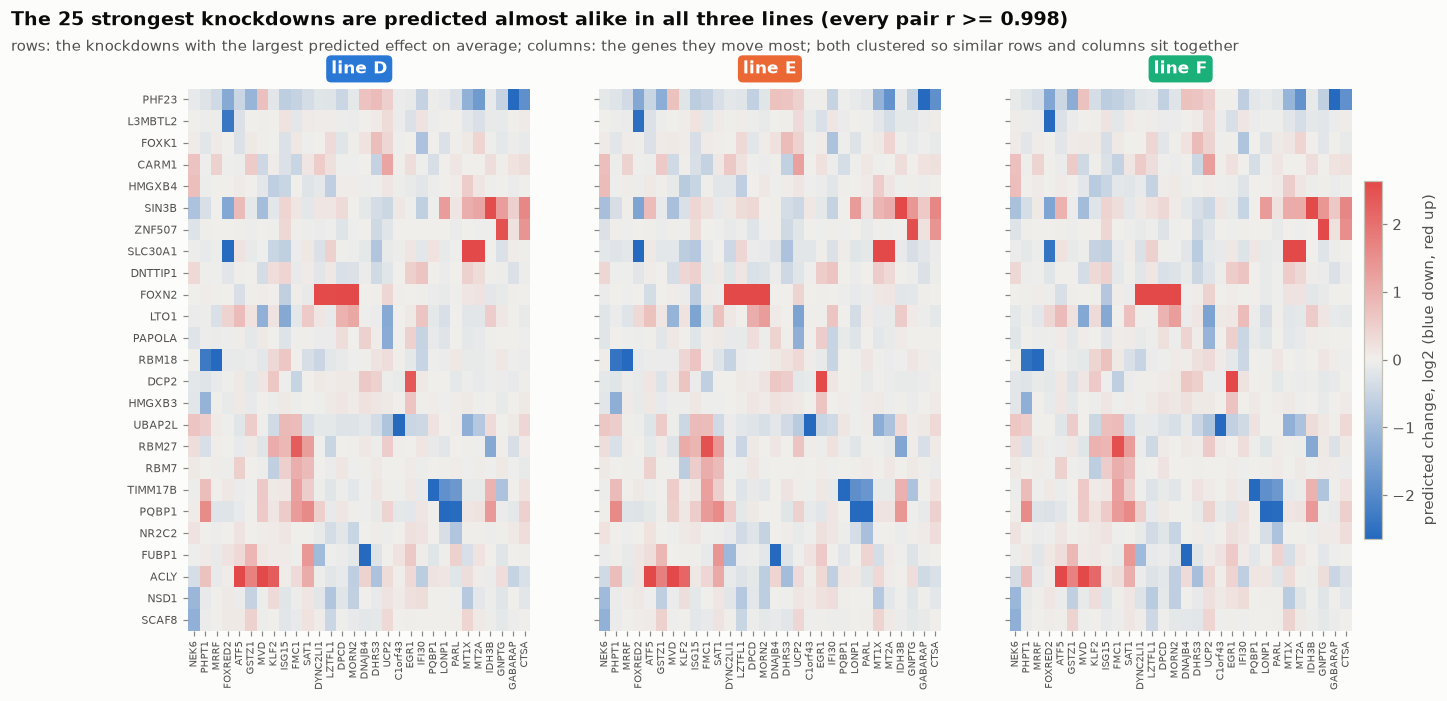

In [84]:
# The figure: the same block of predicted change in every line.
if MODE == "FULL":
    finding = (
        "The 25 strongest knockdowns are predicted almost alike in all three lines "
        f"(every pair r >= {min(pattern_r.values()):.3f})"
    )
    kd_labels = [final_panel[top_kds[k]] for k in row_order]
    gene_labels = [file_genes[top_genes[k]] for k in col_order]
    fig = plot_predicted_heatmaps(shown, line_colour, kd_labels, gene_labels, limit, finding)

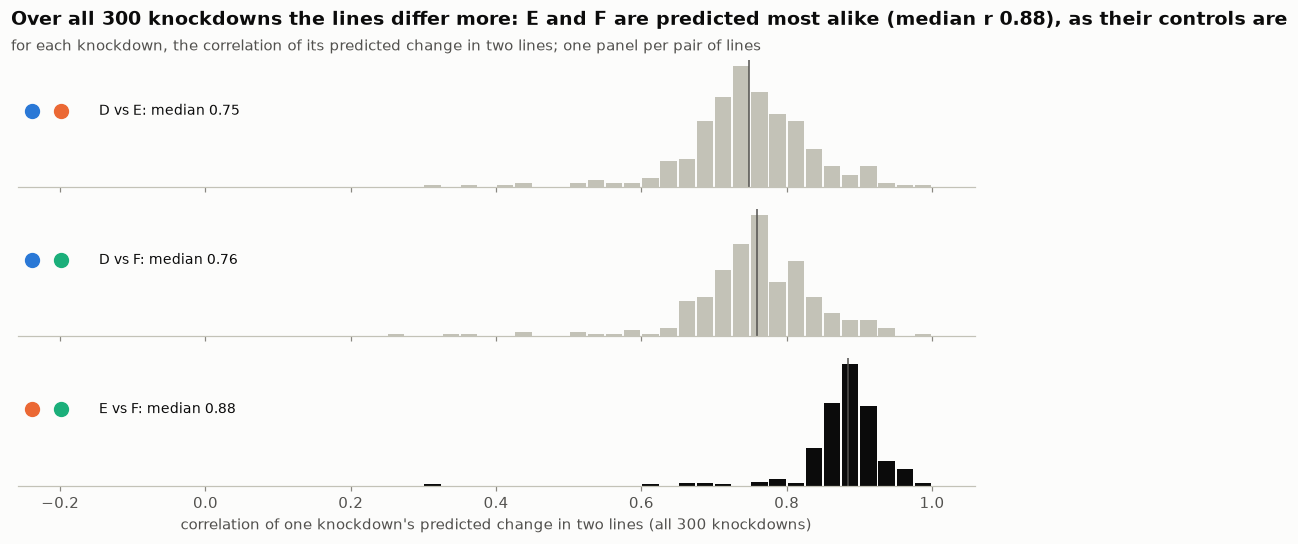

In [85]:
# Over all 300 knockdowns: how alike each pair of lines' predictions are, knockdown by knockdown.
def kd_similarity(a, b):
    """Per knockdown, the correlation of its predicted change in lines a and b (NaN if one is 0)."""
    both = (effect_size[a] > 0) & (effect_size[b] > 0)
    rows = zip(predicted[a], predicted[b], both)
    return np.array([np.corrcoef(x, y)[0, 1] if nonzero else np.nan for x, y, nonzero in rows])


if MODE == "FULL":
    pair_r = {(a, b): kd_similarity(a, b) for a, b in line_pairs}
    most_alike = max(pair_r, key=lambda pair: np.nanmedian(pair_r[pair]))
    median_alike = np.nanmedian(pair_r[most_alike])
    finding = (
        f"Over all 300 knockdowns the lines differ more: {most_alike[0]} and {most_alike[1]} are "
        f"predicted most alike (median r {median_alike:.2f}), as their controls are"
    )
    fig = plot_pair_similarity(pair_r, most_alike, line_colour, finding)

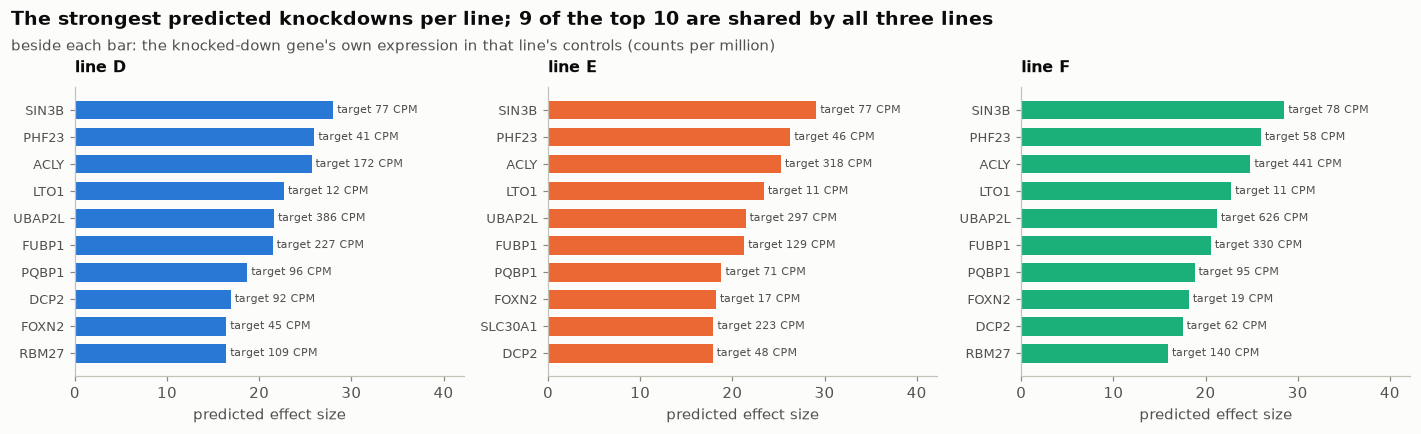

In [86]:
# Each line's 10 strongest knockdowns, and how many all three lines share.
def target_cpm_in(c):
    """Each knockdown's target gene's own CPM in line c's controls (NaN if not on the gene axis)."""
    cpm, index = ctrl_cpm[c], file_gene_index
    return [cpm[index[p]] if p in index else np.nan for p in final_panel]


if MODE == "FULL":
    top_ten = {c: {final_panel[k] for k in np.argsort(-effect_size[c])[:10]} for c in contexts}
    shared_top = set.intersection(*top_ten.values())
    target_cpm = {c: target_cpm_in(c) for c in contexts}
    finding = (
        f"The strongest predicted knockdowns per line; {len(shared_top)} of the top 10 are shared "
        "by all three lines"
    )
    fig = plot_strongest_knockdowns(effect_size, final_panel, target_cpm, line_colour, finding)

In [87]:
# What we learned, in this run's numbers.
if MODE == "FULL":
    alike_a, alike_b = most_alike
    print(
        "What we learned: the file passes every submission check; the 25 strongest knockdowns are "
        f"predicted almost alike in all three lines (r >= {min(pattern_r.values()):.3f}); over all "
        f"300, {alike_a} and {alike_b} are predicted most alike (median r {median_alike:.2f}), as "
        f"their controls are (section 3); {len(shared_top)} of each line's 10 strongest knockdowns "
        "are shared by all three lines."
    )

What we learned: the file passes every submission check; the 25 strongest knockdowns are predicted almost alike in all three lines (r >= 0.998); over all 300, E and F are predicted most alike (median r 0.88), as their controls are (section 3); 9 of each line's 10 strongest knockdowns are shared by all three lines.


**The playbook lesson.** Check the final file again from disk, against every rule, before you package it; and look at
what you predict: the lines that look alike should be predicted alike.

## 14. Packaging and submission

`vcc prep` checks the file against the official gene and knockdown lists and packs it; `vcc submit`
uploads it. Submission runs only with `VCC_SUBMIT=yes`.

In [88]:
if MODE == "FULL":
    vcc = str(Path(sys.executable).parent / "vcc")
    os.umask(0o077)  # the .vcc is a tar of files with their modes: the umask is in its bytes
    h5ad, packed = WORK / "prediction.h5ad", WORK / "prediction.vcc"
    prep_log = vcc_prep(h5ad, PHASE, manifest["contexts"], packed, vcc)
    print("\n".join(ln for ln in prep_log.splitlines() if "targets" in ln or "complete" in ln))
    vcc_sha = sha256_file(packed)
    print("prediction.vcc sha256", vcc_sha)
    print("identical to our reference build's .vcc:", vcc_sha == REFERENCE_VCC_SHA256)
# VCC_SUBMIT=yes and VCC_MODEL_NAME=<the leaderboard name>; the CLI asks for its own login
if SUBMIT:
    vcc_file, model_name = str(WORK / "prediction.vcc"), os.environ["VCC_MODEL_NAME"]
    subprocess.run([vcc, "submit", vcc_file, "-m", model_name], check=True)

✓ prep complete
  targets:       verified against the official list


prediction.vcc sha256 09336ea07b253ed4da9d1369a42af36285fe7700b763418d425f769e118d5497
identical to our reference build's .vcc: True


## 15. Use it on your own line

**The question.** Does the whole pipeline run on a line it has never seen, end to end, and how does it score?

**The experiment.** A worked example on a training line held out completely (HepG2, liver): its control
cells and 20 of its knockdowns form a one-line "phase", every screen of its cell type is removed from the
training data first, and the official scorer compares the prediction with the real perturbed cells.
Replace `OWN_LINE` with any phase directory of your own (controls + a panel) to run it on yours.

*This section scores with the official scorer and runs only when a GPU is visible.*

In [89]:
# The held-out line as a one-line phase (its controls, 20 knockdowns); then the whole pipeline.
OWN_LINE = os.environ.get("VCC_OWN_LINE", "hepg2")
if MODE == "FULL" and GPU:
    own_bench = TABLES / "bench" / OWN_LINE
    full_panel = pd.read_csv(own_bench / "panel.csv")["target_gene"].astype(str).tolist()
    own_panel = sorted(np.random.default_rng(0).choice(full_panel, 20, replace=False).tolist())
    own_work = WORK / f"own_{OWN_LINE}"
    own_phase = fold_phase(own_bench / "reference.h5ad", own_panel, OWN_LINE, own_work / "phase")
    own_inputs = prepare_phase(own_phase, TABLES, own_work, held=HELD_TYPES[OWN_LINE])
    own_inputs["detline"] = probe_phase(own_phase, own_inputs, own_work)
    build_phase(own_phase, own_inputs, own_work / "prediction.h5ad")

directions, gate, cis ready


levels hepg2: median 233


E: 978 keys (165 trained on), training rows per target {'k562': 147, 'cd4t': 139, 'hct116': 143, 'hek293t': 149, 'h1': 160, 'dld1': 39, 'a549': 24, 'rpe1': 55, 'jurkat': 53}


[hepg2] 3540 cells, nnz 13676560


detection line: a 5.0146, b -0.5297


[hepg2] 3540 cells, nnz 12896158


In [90]:
# Scored by the official scorer against the line's real perturbed cells.
if MODE == "FULL" and GPU:
    own_reference = own_bench / "reference.h5ad"
    own_prediction = own_work / "prediction.h5ad"
    own_scores = score_fold(own_prediction, own_phase, own_reference, None, own_work / "score")
    print(pd.Series(own_scores).round(3).to_string())

pds        1.213
mse        0.000
nmae      -0.102
fid        0.226
reach     -0.085
jac        0.490
overall    0.290


In [91]:
# Measured and predicted change of each knockdown, over genes the line expresses (CPM > 20),
# the knocked-down gene itself left out.
if MODE == "FULL" and GPU:
    own_cells = ad.read_h5ad(own_reference)
    own_labels = own_cells.obs["target_gene"].astype(str).to_numpy()
    own_counts = sp.csr_matrix(own_cells.X)
    own_cpm = mean_cpm(own_counts[own_labels == "non-targeting"])
    own_keys, own_sums, own_genes = group_sums(own_prediction)
    own_row = {key[1]: i for i, key in enumerate(own_keys)}  # knockdown -> row of own_sums
    own_well = own_cpm > 20
    kd_cpm = [mean_cpm(own_counts[own_labels == p]) for p in own_panel]
    own_measured = np.vstack([np.log2((x + 1) / (own_cpm + 1)) for x in kd_cpm])[:, own_well]
    own_pred_cpm = [own_sums[own_row[p]] / own_sums[own_row[p]].sum() * 1e6 for p in own_panel]
    own_predicted = np.vstack([np.log2((x + 1) / (own_cpm + 1)) for x in own_pred_cpm])[:, own_well]
    well_index = {g: i for i, g in enumerate(np.array(own_genes)[own_well])}
    for row, p in enumerate(own_panel):
        if p in well_index:
            own_measured[row, well_index[p]] = own_predicted[row, well_index[p]] = 0.0

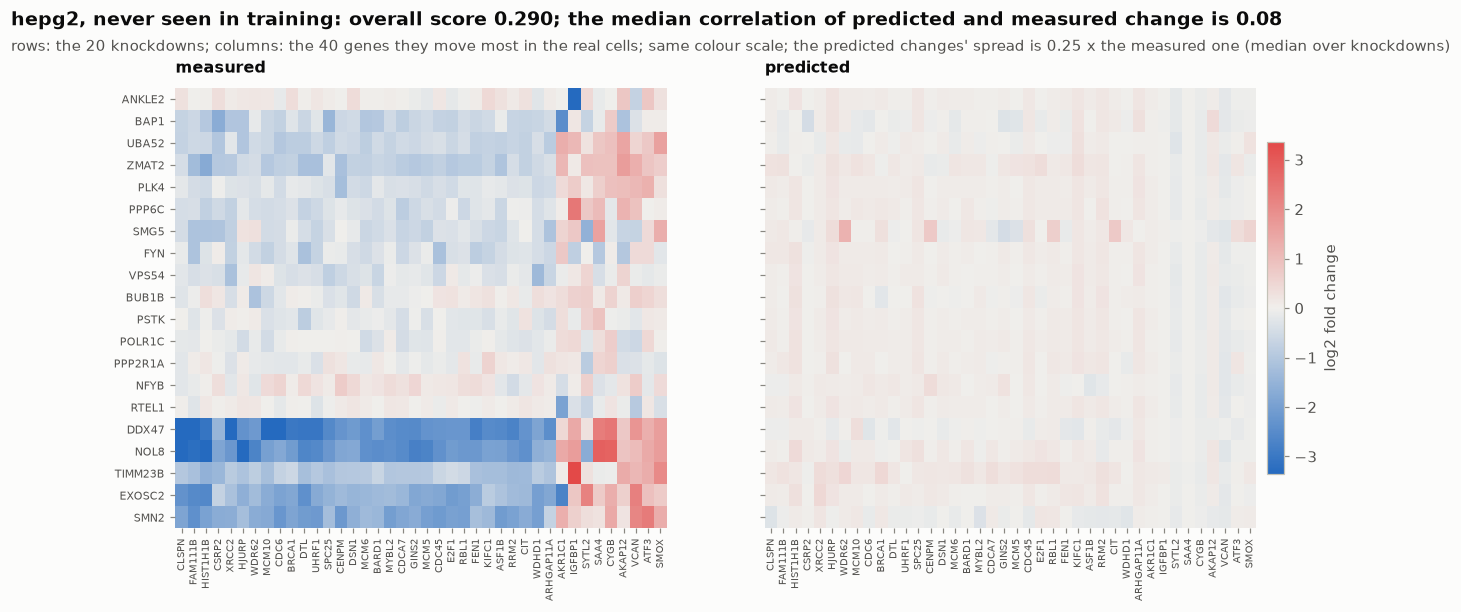

In [92]:
# How well the prediction tracks the measurement and how large it is; then both, ordered.
if MODE == "FULL" and GPU:
    own_r = [np.corrcoef(own_measured[r], own_predicted[r])[0, 1] for r in range(len(own_panel))]
    spread = own_predicted.std(1) / np.maximum(own_measured.std(1), 1e-12)  # per knockdown
    own_spread = float(np.median(spread))  # predicted spread over measured, the median
    top_moved = np.argsort(-np.abs(own_measured).sum(0))[:40]  # the 40 genes moved most
    own_rows = leaves_list(linkage(own_measured[:, top_moved], "average"))
    own_cols = top_moved[leaves_list(linkage(own_measured[:, top_moved].T, "average"))]
    own_limit = float(np.percentile(np.abs(own_measured[:, top_moved]), 99))
    measured_shown = own_measured[np.ix_(own_rows, own_cols)]
    predicted_shown = own_predicted[np.ix_(own_rows, own_cols)]
    finding = (
        f"{OWN_LINE}, never seen in training: overall score {own_scores['overall']:.3f}; the "
        f"median correlation of predicted and measured change is {np.nanmedian(own_r):.2f}"
    )
    kd_names = [own_panel[r] for r in own_rows]
    gene_names = np.array(own_genes)[own_well][own_cols]
    shown_own = (measured_shown, predicted_shown, kd_names, gene_names, own_limit, own_spread)
    fig = plot_own_line(*shown_own, finding)
else:
    print("skipped: needs the scorer's GPU engine (MODE FULL and a visible GPU)")

In [93]:
# What we learned, in this run's numbers.
if MODE == "FULL" and GPU:
    too_little = ": stage 1 sizes its predictions to the line's noise budget, and here that errs "
    too_little += "towards too little change rather than too much."
    ending = too_little if own_spread < 0.8 else "."
    print(
        f"What we learned: on {OWN_LINE}, held out with every screen of its cell type, the "
        f"pipeline scores {own_scores['overall']:.3f} overall on 20 knockdowns; the median "
        f"correlation of predicted and measured change is {np.nanmedian(own_r):.2f}, and the "
        f"predicted changes are {own_spread:.2f} times as spread as the measured ones{ending}"
    )
    EVIDENCE[15] = f"{OWN_LINE}, never seen in training: overall {own_scores['overall']:.3f}"

What we learned: on hepg2, held out with every screen of its cell type, the pipeline scores 0.290 overall on 20 knockdowns; the median correlation of predicted and measured change is 0.08, and the predicted changes are 0.25 times as spread as the measured ones: stage 1 sizes its predictions to the line's noise budget, and here that errs towards too little change rather than too much.


**The playbook lesson.** Run the whole pipeline on a line you can score before trusting it on one you cannot.

## The playbook

Every section's lesson as one checklist, each with the evidence this run produced. The rules are general; the
numbers are ours.

In [94]:
# section 12 quotes them; nothing to compute
EVIDENCE[12] = "seven closed ideas, quoted from our records"
NOT_RUN = "(this section's numbers need FULL mode, and a GPU where it scores)"
PLAYBOOK = {
    1: "Write down the input and the output, with their exact shapes, before anything else.",
    2: "Build the scorer's intuition before the model: a metric is a program you can test on "
    "cases you construct.",
    3: "Identify your test distribution with the unlabelled data you are given.",
    4: "Inventory the data before choosing a model; data, not architecture, is usually the "
    "bottleneck.",
    5: "Measure the noise ceiling before you measure a model.",
    6: "Measure how well effects transfer, on all the data you have, before deciding how to "
    "weight the sources.",
    7: "A clean negative result with a positive control is knowledge.",
    8: "The harness must look like the test; never tune on the leaderboard.",
    9: "Match the evaluation's statistic, not only the target's mean.",
    10: "Add a piece only if it beats the noise floor; delete the ones that don't.",
    11: "The last step decides what the metric sees: check the generator against real cells on "
    "its own.",
    12: "In the small-data regime simple, well-measured models win; record negatives so nobody "
    "repeats them.",
    13: "Check the final file again from disk, against every rule, before you package it.",
    15: "Run the whole pipeline on a line you can score before trusting it on one you cannot.",
}
checklist = [
    f"- [x] **{rule}** (section {section}) *{EVIDENCE.get(section, NOT_RUN)}*"
    for section, rule in PLAYBOOK.items()
]
display(Markdown("\n".join(checklist)))

- [x] **Write down the input and the output, with their exact shapes, before anything else.** (section 1) *3 lines x 300 knockdowns x 400 cells x 18,533 genes*
- [x] **Build the scorer's intuition before the model: a metric is a program you can test on cases you construct.** (section 2) *right means, wrong shape: MSE 1.00 but JAC 0.06*
- [x] **Identify your test distribution with the unlabelled data you are given.** (section 3) *D: MOLM-13 (Myeloid); E: U-87 MG (CNS/Brain); F: no clear match*
- [x] **Inventory the data before choosing a model; data, not architecture, is usually the bottleneck.** (section 4) *300 of 300 knockdowns measured somewhere; no screen of a brain line*
- [x] **Measure the noise ceiling before you measure a model.** (section 5) *median reliability K562 0.24, Jurkat 0.22, HepG2 0.38, RPE1 0.43, H1 (Flex) 0.90, KOLF iPSC 0.22*
- [x] **Measure how well effects transfer, on all the data you have, before deciding how to weight the sources.** (section 6) *noise-corrected transfer 0.43 within a tissue, 0.43 across*
- [x] **A clean negative result with a positive control is knowledge.** (section 7) *planted r 0.44, real 0.10, random 0.00*
- [x] **The harness must look like the test; never tune on the leaderboard.** (section 8) *six held-out lines: final 0.391, borrowed consensus 0.306*
- [x] **Match the evaluation's statistic, not only the target's mean.** (section 9) *with true means: 13,190 false calls (naive cells) against 2,017 (ours)*
- [x] **Add a piece only if it beats the noise floor; delete the ones that don't.** (section 10) *3 of 12 pieces above the noise band (0.0022)*
- [x] **The last step decides what the metric sees: check the generator against real cells on its own.** (section 11) *spread within x1.4 for 95% of gene x knockdown pairs*
- [x] **In the small-data regime simple, well-measured models win; record negatives so nobody repeats them.** (section 12) *seven closed ideas, quoted from our records*
- [x] **Check the final file again from disk, against every rule, before you package it.** (section 13) *10 of 10 checks pass*
- [x] **Run the whole pipeline on a line you can score before trusting it on one you cannot.** (section 15) *hepg2, never seen in training: overall 0.290*

## Appendix: building the reference tables from public downloads

Everything the pipeline reads under `TABLES` is built here from public files: one log2 fold-change table per
screen (knockdowns x the 18,533 genes, with its control CPM, cell counts and, for the screens added late, the
control-cell count and depth in a `.json`), the training lines reshaped like the challenge, their split halves
(section 5), every screen's principal axes and the bench controls' overdispersion. Each rebuilt table is compared
with the shipped one array by array: an `.npz` stores its write time, so its bytes differ by construction; every
array must be equal, or the cell prints the largest difference.

One loader per source family, with shared helpers (in the package's `rebuild` module). The downloads resume when interrupted and are
throttled to 50 MB/s. This runs only with `VCC_MODE=FULL` and `VCC_REBUILD_TABLES=yes`: the size of the downloads
is printed first.

In [95]:
REBUILD = MODE == "FULL" and os.environ.get("VCC_REBUILD_TABLES", "") == "yes"
DOWNLOADS = Path(os.environ.get("VCC_DOWNLOADS", DATA / "downloads"))
REBUILT = WORK / "tables_rebuilt"
NOT_REBUILT = {
    "kolf": "KOLF2.1J iPSC atlas (189 GB download)",
    "orion_hct116": "Orion HCT116 (126 GB download)",
    "orion_hek293t": "Orion HEK293T (same download)",
}
checks: dict = {}


def check(name: str, table: dict, held: Path | None = None) -> None:
    """Save a rebuilt table beside the others and compare it with the shipped one."""
    held = held or TABLES / f"{name}.npz"
    out = REBUILT / Path(held).relative_to(TABLES).with_suffix("")
    out.parent.mkdir(parents=True, exist_ok=True)
    save_table(table, out)
    rep = same_table(table, held)
    checks[name] = rep
    bad = {k: v for k, v in rep.items() if not v["equal"]}
    print(f"{name}: " + ("every array equal" if not bad else f"DIFFERS {bad}"))


if REBUILD:
    total = sum(size for _, size, _ in PUBLIC_FILES.values())
    print(f"{len(PUBLIC_FILES)} public files, {total / 1e9:.0f} GB, into {DOWNLOADS}")
    axis_genes = pd.read_csv(PHASE / "gene_names.csv")["gene_name"].astype(str).tolist()
    gmapA = GeneMap(axis_genes, fetch("hgnc_complete_set_2026-09-04.txt", DOWNLOADS))
else:
    print("skipped: set VCC_MODE=FULL and VCC_REBUILD_TABLES=yes to rebuild the tables")

skipped: set VCC_MODE=FULL and VCC_REBUILD_TABLES=yes to rebuild the tables


**The bulk and published screens**: the K562 genome-wide screen's pseudobulk, the 30 pathway screens (published
DE tables) and the transcription start sites (for the neighbour prior).

In [96]:
if REBUILD:
    check(
        "k562gwps_bulk", table_gwps_bulk(fetch("K562_gwps_raw_bulk_01.h5ad", DOWNLOADS), axis_genes)
    )
    for name, t in tables_jiang(fetch("DE_results_all_pathway.zip", DOWNLOADS), gmapA).items():
        check(name, t)
    (REBUILT / "tss.csv").parent.mkdir(parents=True, exist_ok=True)
    tss_table(fetch("gencode.v49.basic.annotation.gtf.gz", DOWNLOADS)).to_csv(
        REBUILT / "tss.csv", index=False
    )
    checks["tss"] = {
        "csv": {"equal": sha256_file(REBUILT / "tss.csv") == sha256_file(TABLES / "tss.csv")}
    }
    print("tss.csv:", "same bytes" if checks["tss"]["csv"]["equal"] else "DIFFERS")

**The single-cell screens of other lines**: K562 on Flex (a Seurat file), A549 (CRISPRi, and the knockout
atlas), A375 (PerturbFate), H1 hESC (genome-scale, 85 lanes) and DLD-1.

In [97]:
if REBUILD:
    spill = WORK / "spill"
    check(
        "viperturb",
        table_viperturb(fetch("genome_wide_filtered.rds", DOWNLOADS), gmapA, spill / "viperturb"),
    )
    for f in ("GSE337804_A549_ch_1.RDS.h5ad", "GSE337804_A549_ch_2.RDS.h5ad"):
        fetch(f, DOWNLOADS)
    check("a549_myllia", table_myllia(DOWNLOADS, axis_genes))
    for f in [k for k in PUBLIC_FILES if k.startswith("GSE291147")] + [
        "GSM7056149_sciPlexGxE_2_gene.annotations.txt.gz",
        "gencode.v49.basic.annotation.gtf.gz",
    ]:
        fetch(f, DOWNLOADS)
    check("a375_perturbfate", table_perturbfate(DOWNLOADS, axis_genes, spill / "perturbfate"))
    for f in (
        "GSE345058_cell_annotations.csv.gz",
        "GSE345058_gene_annotations.csv.gz",
        "GSE345058_raw_counts.mtx.gz",
    ):
        fetch(f, DOWNLOADS)
    check("a549_ko", table_a549_ko(DOWNLOADS, axis_genes))
    for f, _, _ in HESC_LANES:
        fetch(f, DOWNLOADS / "hesc")
    check("hesc_gs", table_hesc(DOWNLOADS / "hesc", gmapA))
    dld = DOWNLOADS / "dld1"
    for f in (
        "filelist.txt",
        "GSE337988_sublib2_samplesheet.csv.gz",
        "GSE337988_NGS6475_crispr_demux_index_map_prod.csv.gz",
        "GSE337988_sublib2_processed_objects_Low_se.rds",
    ):
        fetch(f, dld)
    for ch in dld1_channels(dld):
        fetch(ch["rna"], dld)
    check("dld1_gx", table_dld1(dld, gmapA, spill / "dld1"))

**The training lines** (K562, RPE1, HepG2, Jurkat and the 2025 challenge's H1): each line reshaped like the
challenge (the panel, 400 cells per knockdown, 18,400 controls, depth thinned to a median of 20,000), its table,
its split halves, and the controls' overdispersion. The extra keys of section 13's learned blend are these panels.

In [98]:
if REBUILD:
    refs = {}
    for line in ("h1", "k562", "rpe1", "hepg2", "jurkat"):
        if line == "h1":
            z = fetch("competition_support_set.zip", DOWNLOADS)
            if not (DOWNLOADS / "competition_train.h5").exists():
                with (
                    zipfile.ZipFile(z) as zf,
                    zf.open("competition_support_set/competition_train.h5") as src,
                    open(DOWNLOADS / "competition_train.h5", "wb") as dst,
                ):
                    shutil.copyfileobj(src, dst)
        else:
            fetch(BENCH_LINES[line][0], DOWNLOADS)
        X, labels = load_line(line, DOWNLOADS, axis_genes)
        names = ad.read_h5ad(DOWNLOADS / BENCH_LINES[line][0], backed="r").obs_names.astype(str)
        ref, panel = build_reference(X, labels, names, genes=axis_genes)
        held = ad.read_h5ad(TABLES / "bench" / line / "reference.h5ad")
        same = {
            "panel": list(panel)
            == pd.read_csv(TABLES / "bench" / line / "panel.csv")["target_gene"]
            .astype(str)
            .tolist(),
            "cells": list(ref.obs_names) == list(held.obs_names),
            "genes": list(ref.var_names) == list(held.var_names),
            "counts": bool(ref.X.shape == held.X.shape and (ref.X != held.X).nnz == 0),
        }
        checks[f"reference_{line}"] = {k: {"equal": v} for k, v in same.items()}
        print(
            f"{line} reference:",
            "panel, cells, genes and counts equal" if all(same.values()) else f"DIFFERS {same}",
        )
        refs[line] = REBUILT / "bench" / line / "reference.h5ad"
        refs[line].parent.mkdir(parents=True, exist_ok=True)
        ref.write_h5ad(refs[line])
        pd.DataFrame({"target_gene": panel}).to_csv(refs[line].parent / "panel.csv", index=False)
        lab_r = ref.obs["target_gene"].astype(str).to_numpy()
        t = table_bench(line, X, labels, mean_cpm(ref.X[lab_r == "non-targeting"]))
        check(f"bench_{line}", t)
        check(
            f"halves_{line}",
            halves_line(line, DOWNLOADS, gmapA, set(t["target"])),
            TABLES / "halves" / ("h1train.npz" if line == "h1" else f"bench_{line}.npz"),
        )
        del X, ref, held
    phiA = table_phi(refs)
    np.savez(REBUILT / "phi.npz", **phiA)
    check("phi", phiA)
    panels = {
        ln: set(pd.read_csv(refs[ln].parent / "panel.csv")["target_gene"].astype(str))
        for ln in refs
    }
    checks["e_keys"] = {
        "train": {"equal": E_TRAIN_EXTRA == sorted(panels["h1"])},
        "rows": {
            "equal": E_ROW_EXTRA
            == sorted(set().union(*(panels[ln] for ln in ("k562", "rpe1", "hepg2", "jurkat"))))
        },
    }
    print(
        "learned blend's extra keys = the H1 panel and the four other panels:",
        all(v["equal"] for v in checks["e_keys"].values()),
    )

**The H1 held-out splits and the CD4 T screen**: the 2025 challenge's validation and test H1 cells, and the
genome-wide CD4 T pseudobulk (three conditions, four donors, each knockdown against its own donor mix).

In [99]:
if REBUILD:
    for f in ("adata_Validation.h5ad", "adata_Test.h5ad"):
        fetch(f, DOWNLOADS)
    check("arc_h1", table_arc_h1(DOWNLOADS, gmapA))
    fetch("GWCD4i.pseudobulk_merged.h5ad", DOWNLOADS)
    for name, t in tables_cd4(DOWNLOADS, gmapA).items():
        check(name, t)

**Each screen's principal axes**, from the rebuilt tables (the shipped ones for the screens not rebuilt here).

In [100]:
if REBUILD:
    for f in ["phi.npz", *(f"{n}.{x}" for n in NOT_REBUILT for x in ("npz", "json"))]:
        if not (REBUILT / f).exists() and (TABLES / f).exists():
            shutil.copy(TABLES / f, REBUILT / f)
    pc_names = sorted(p.stem for p in (TABLES / "srcpc").glob("*.npy"))
    srcsA = open_tables(REBUILT, pc_names)
    (REBUILT / "srcpc").mkdir(exist_ok=True)
    for n in pc_names:
        axesA = source_pc_axes(srcsA, n, axis_genes)
        np.save(REBUILT / "srcpc" / f"{n}.npy", axesA)
        held = np.load(TABLES / "srcpc" / f"{n}.npy")
        checks[f"srcpc_{n}"] = {
            "axes": {"equal": bool(axesA.shape == held.shape and np.array_equal(axesA, held))}
        }
    print(
        "principal axes equal for",
        sum(c["axes"]["equal"] for k, c in checks.items() if k.startswith("srcpc_")),
        "of",
        len(pc_names),
        "screens",
    )

In [101]:
if REBUILD:
    summary = pd.DataFrame(
        [
            {
                "table": k,
                "arrays": len(v),
                "equal": all(x["equal"] for x in v.values()),
                "max |diff|": max((x.get("max_abs_diff", 0.0) for x in v.values()), default=0.0),
            }
            for k, v in checks.items()
        ]
    )
    for n, why in NOT_REBUILT.items():
        summary.loc[len(summary)] = {"table": n, "arrays": 0, "equal": None, "max |diff|": None}
        print(f"{n}: shipped as built, not rebuilt here ({why})")
    print(summary.to_string(index=False))
    print(
        "What we learned:",
        f"{int(summary['equal'].eq(True).sum())} of {int(summary['equal'].notna().sum())} rebuilt "
        "tables equal the shipped ones in every array.",
    )